# Transdüktif Model (MLGANN gibi)	İndüktif Model

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch_geometric.nn import SAGEConv
from torch_geometric.utils import negative_sampling
from torch_geometric.data import Data
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt


# Transdüktif Model örneği

In [14]:

# -------------------------------
# 1. SENTETİK VERİ: 5 düğüm, her biri 3 özellik
# -------------------------------
num_nodes = 5
node_features = torch.randn(num_nodes, 3)  # 5x3

# Gerçek kenarlar (tüm bilinen etkileşimler) - örnek bir yapı
# 0-1, 1-2, 2-3, 3-4, 0-4, 1-3 (toplam 6 kenar)
all_edges = torch.tensor([[0,1,2,3,0,1],
                          [1,2,3,4,4,3]], dtype=torch.long)  # shape (2,6)

# Eğitim ve test kenarlarını ayır (transdüktif validasyon)
# Rastgele 2 kenarı test için gizle, geri kalan 4'ü eğitim için kullan
np.random.seed(42)
num_edges = all_edges.size(1)
indices = np.random.permutation(num_edges)
train_mask = indices[:4]   # ilk 4 kenar eğitim
test_mask = indices[4:]    # son 2 kenar test

train_edges = all_edges[:, train_mask]
test_edges = all_edges[:, test_mask]

print("Eğitim kenarları (bilinen):")
print(train_edges.t().tolist())
print("Test kenarları (gizli, tahmin edilecek):")
print(test_edges.t().tolist())

# -------------------------------
# 2. BASİT BİR TRANSDÜKTİF MODEL
# Düğüm embedding'lerini doğrudan öğrenen bir matris (GNN yok, sadece embedding tablosu)
# Bu, transdüktif yaklaşımın en basit halidir.
# -------------------------------


Eğitim kenarları (bilinen):
[[0, 1], [1, 2], [1, 3], [2, 3]]
Test kenarları (gizli, tahmin edilecek):
[[0, 4], [3, 4]]


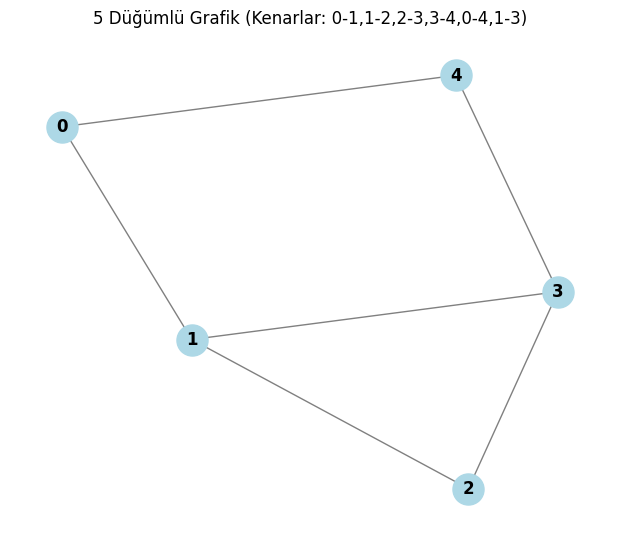

In [20]:
edges1 =  all_edges.t().tolist() 
# Grafiği oluştur
G1 = nx.Graph()
G1.add_edges_from(edges1)

# Çiz
plt.figure(figsize=(6,5))
nx.draw(G1, with_labels=True, node_color='lightblue', node_size=500, font_weight='bold', edge_color='gray')
plt.title("5 Düğümlü Grafik (Kenarlar: 0-1,1-2,2-3,3-4,0-4,1-3)")
plt.show()

In [6]:
class TransductiveLinkPredictor(nn.Module):
    def __init__(self, num_nodes, embedding_dim):
        super().__init__()
        self.node_embedding = nn.Embedding(num_nodes, embedding_dim)
        # embedding'leri rastgele başlat
        nn.init.xavier_uniform_(self.node_embedding.weight)
    
    def forward(self, edge_index):
        # edge_index: (2, E) şeklinde
        src, dst = edge_index
        src_emb = self.node_embedding(src)
        dst_emb = self.node_embedding(dst)
        # nokta çarpım ile skor
        scores = (src_emb * dst_emb).sum(dim=1)
        return scores
    
    def predict_link(self, src, dst):
        # İki düğüm arasındaki bağlantı olasılığı
        src_emb = self.node_embedding(src)
        dst_emb = self.node_embedding(dst)
        score = (src_emb * dst_emb).sum()
        return torch.sigmoid(score)

model = TransductiveLinkPredictor(num_nodes, embedding_dim=8)
optimizer = optim.Adam(model.parameters(), lr=0.1)

# -------------------------------
# 3. EĞİTİM (SADECE EĞİTİM KENARLARI KULLANILIR)
# -------------------------------
def train():
    model.train()
    optimizer.zero_grad()
    
    # Pozitif kenar skorları (eğitim kenarları)
    pos_scores = model(train_edges)
    pos_loss = -torch.log(torch.sigmoid(pos_scores) + 1e-15).mean()
    
    # Negatif örnekleme: var olmayan kenarlar (eğitim setinde olmayan ve test setinden bağımsız)
    # Basitçe rastgele iki düğüm seçip, eğitim kenarlarıyla çakışmamasına dikkat edelim
    # Ancak burada kolaylık olsun diye tamamen rastgele negatif kenar üretiyoruz.
    neg_src = torch.randint(0, num_nodes, (train_edges.size(1),))
    neg_dst = torch.randint(0, num_nodes, (train_edges.size(1),))
    # Aynı düğüm olmasın ve eğitim kenarlarıyla aynı olmasın (basit kontrol)
    neg_edges = torch.stack([neg_src, neg_dst])
    neg_scores = model(neg_edges)
    neg_loss = -torch.log(1 - torch.sigmoid(neg_scores) + 1e-15).mean()
    
    loss = pos_loss + neg_loss
    loss.backward()
    optimizer.step()
    return loss.item()

print("\nEğitim başlıyor...")
for epoch in range(300):
    loss = train()
    if epoch % 100 == 0:
        print(f"Epoch {epoch:3d} | Loss: {loss:.4f}")




Eğitim başlıyor...
Epoch   0 | Loss: 1.8989
Epoch 100 | Loss: 0.8711
Epoch 200 | Loss: 1.3358


In [8]:
# -------------------------------
# 4. TEST: GİZLİ KENARLARI TAHMİN ET
# -------------------------------
model.eval()
with torch.no_grad():
    print("\n--- Gizli Kenarların Tahmini ---")
    for i in range(test_edges.size(1)):
        src, dst = test_edges[0, i].item(), test_edges[1, i].item()
        prob = model.predict_link(torch.tensor(src), torch.tensor(dst)).item()
        print(f"Kenar ({src}-{dst}) tahmin olasılığı: {prob:.4f}")
    
    # Ayrıca modelin daha önce hiç görmediği bir çift için tahmin yapalım (örneğin 0-2)
    prob_02 = model.predict_link(torch.tensor(0), torch.tensor(2)).item()
    print(f"\nHiç görülmemiş kenar (0-2) tahmin olasılığı: {prob_02:.4f}")


--- Gizli Kenarların Tahmini ---
Kenar (0-4) tahmin olasılığı: 0.4459
Kenar (3-4) tahmin olasılığı: 0.3126

Hiç görülmemiş kenar (0-2) tahmin olasılığı: 0.5300


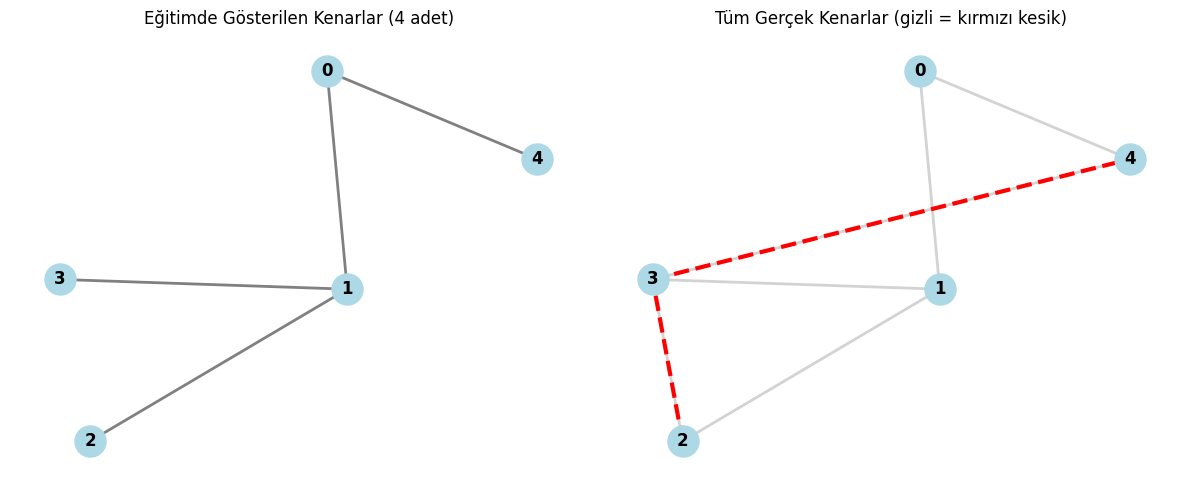

In [28]:
import networkx as nx
import matplotlib.pyplot as plt

# Düğüm sayısı
num_nodes = 5

# Eğitim kenarları (modele gösterilenler)
train_edges = [(0,1), (1,2), (0,4), (1,3)]   # örnekteki 4 kenar

# Test kenarları (gizli olanlar)
test_edges = [(2,3), (3,4)]                  # 2 kenar

# Tüm kenarlar (gerçek ağ)
all_edges = train_edges + test_edges

# -------------------------------
# 1. EĞİTİM GRAFİĞİ (sadece gösterilen kenarlar)
# -------------------------------
G_train = nx.Graph()
G_train.add_nodes_from(range(num_nodes))
G_train.add_edges_from(train_edges)

# -------------------------------
# 2. TÜM GERÇEK GRAFİK (eğitim + gizli)
# -------------------------------
G_all = nx.Graph()
G_all.add_nodes_from(range(num_nodes))
G_all.add_edges_from(all_edges)

# -------------------------------
# GÖRSELLEŞTİRME (yan yana)
# -------------------------------
fig, (ax1, ax2,) = plt.subplots(1, 2,  figsize=(12, 5))

# Ortak düzen için layout
pos = nx.spring_layout(G_all, seed=42)

# Eğitim grafiği
nx.draw_networkx_nodes(G_train, pos, node_color='lightblue', node_size=500, ax=ax1)
nx.draw_networkx_labels(G_train, pos, font_size=12, font_weight='bold', ax=ax1)
nx.draw_networkx_edges(G_train, pos, edge_color='gray', width=2, ax=ax1)
ax1.set_title("Eğitimde Gösterilen Kenarlar (4 adet)", fontsize=12)
ax1.axis('off')

# Tüm gerçek grafik (gizli kenarlar farklı renkte)
nx.draw_networkx_nodes(G_all, pos, node_color='lightblue', node_size=500, ax=ax2)
nx.draw_networkx_labels(G_all, pos, font_size=12, font_weight='bold', ax=ax2)
# Önce tüm kenarları gri çiz
nx.draw_networkx_edges(G_all, pos, edgelist=all_edges, edge_color='lightgray', width=2, ax=ax2)
# Sonra gizli kenarları kırmızı ve kalın çiz
nx.draw_networkx_edges(G_all, pos, edgelist=test_edges, edge_color='red', width=3, style='dashed', ax=ax2)
ax2.set_title("Tüm Gerçek Kenarlar (gizli = kırmızı kesik)", fontsize=12)
ax2.axis('off')







plt.tight_layout()
plt.show()

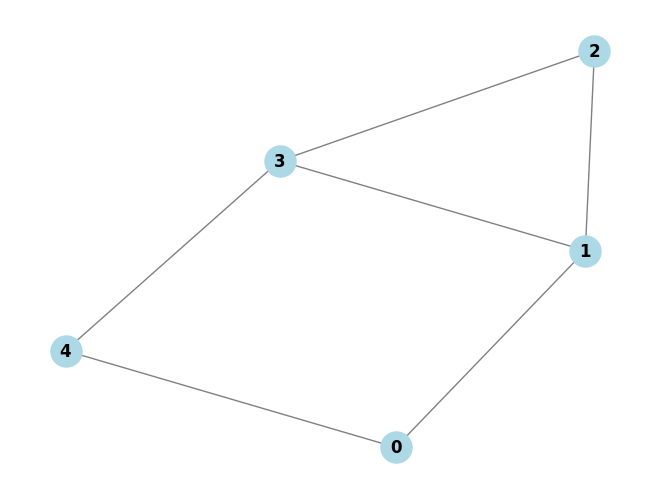

In [30]:
nx.draw(G1, with_labels=True, node_color='lightblue', node_size=500, font_weight='bold', edge_color='gray')


# İndüktif örneği

In [32]:
# İndüktif örneği
# -------------------------------
# 1. SENTETİK VERİ OLUŞTURMA
# -------------------------------
# 5 düğüm, her biri 3 özellik
num_nodes = 5
node_features = torch.randn(num_nodes, 3)  # 5x3
print(node_features)

# Bağlantılar (kenarlar) - basit bir yapı: 0-1, 1-2, 2-3, 3-4, 0-4
edge_index = torch.tensor([[0, 1, 2, 3, 0],
                           [1, 2, 3, 4, 4]], dtype=torch.long)

# Data objesi (grafik)
data = Data(x=node_features, edge_index=edge_index)


# -------------------------------
# 2. BASIT BİR İNDÜKTİF GNN MODELİ (GraphSAGE)
# -------------------------------
class InductiveGNN(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super().__init__()
        self.conv1 = SAGEConv(in_channels, hidden_channels)
        self.conv2 = SAGEConv(hidden_channels, out_channels)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index).relu()
        x = self.conv2(x, edge_index)
        return x

model = InductiveGNN(in_channels=3, hidden_channels=16, out_channels=8)
optimizer = optim.Adam(model.parameters(), lr=0.01)

# -------------------------------
# 3. LİNK PREDICTION EĞİTİMİ
# -------------------------------
# Eğitim için pozitif kenarlar = mevcut edge_index
pos_edge_index = data.edge_index

# Negatif örnekler (eğitim sırasında her epoch'ta yeniden örnekleyelim)
def train():
    model.train()
    optimizer.zero_grad()
    
    # Düğüm embedding'lerini hesapla
    embed = model(data.x, data.edge_index)
  
    
    # Pozitif kenarlar için skor (nokta çarpım)
    pos_out = (embed[pos_edge_index[0]] * embed[pos_edge_index[1]]).sum(dim=1)
    pos_loss = -torch.log(torch.sigmoid(pos_out) + 1e-15).mean()
    
    # Negatif örnekleme (aynı sayıda)
    neg_edge_index = negative_sampling(pos_edge_index, num_nodes=data.num_nodes, num_neg_samples=pos_edge_index.size(1))
    neg_out = (embed[neg_edge_index[0]] * embed[neg_edge_index[1]]).sum(dim=1)
    neg_loss = -torch.log(1 - torch.sigmoid(neg_out) + 1e-15).mean()
    
    loss = pos_loss + neg_loss
    loss.backward()
    optimizer.step()
    return loss.item()



tensor([[-0.4930, -0.3263,  0.0330],
        [ 0.7762, -0.3658, -1.1477],
        [-1.3111, -1.4996, -0.0021],
        [ 0.0688, -0.2429,  0.1481],
        [ 1.6757,  0.8699, -0.4791]])


In [35]:
# Önceki koddan devamla
print("Düğüm özellikleri (data.x):")
print(data.x)  # shape: [num_nodes, num_node_features]

print(f"\nHer düğümdeki özellik sayısı: {data.num_node_features}")
print(f"Toplam düğüm sayısı: {data.num_nodes}")

# Her bir düğümün özelliklerini ayrı ayrı yazdırmak için
for i in range(data.num_nodes):
    print(f"Düğüm {i} özellikleri: {data.x[i].tolist()}")

Düğüm özellikleri (data.x):
tensor([[-0.4930, -0.3263,  0.0330],
        [ 0.7762, -0.3658, -1.1477],
        [-1.3111, -1.4996, -0.0021],
        [ 0.0688, -0.2429,  0.1481],
        [ 1.6757,  0.8699, -0.4791]])

Her düğümdeki özellik sayısı: 3
Toplam düğüm sayısı: 5
Düğüm 0 özellikleri: [-0.49304014444351196, -0.3262580931186676, 0.0330130010843277]
Düğüm 1 özellikleri: [0.7761958241462708, -0.36575424671173096, -1.147714376449585]
Düğüm 2 özellikleri: [-1.3111357688903809, -1.4995568990707397, -0.002115195617079735]
Düğüm 3 özellikleri: [0.06878155469894409, -0.24293871223926544, 0.14805176854133606]
Düğüm 4 özellikleri: [1.675694465637207, 0.8698775172233582, -0.47908949851989746]


(-1.200569666651054,
 1.1115751097767976,
 -1.1985738193163336,
 1.089753050900463)

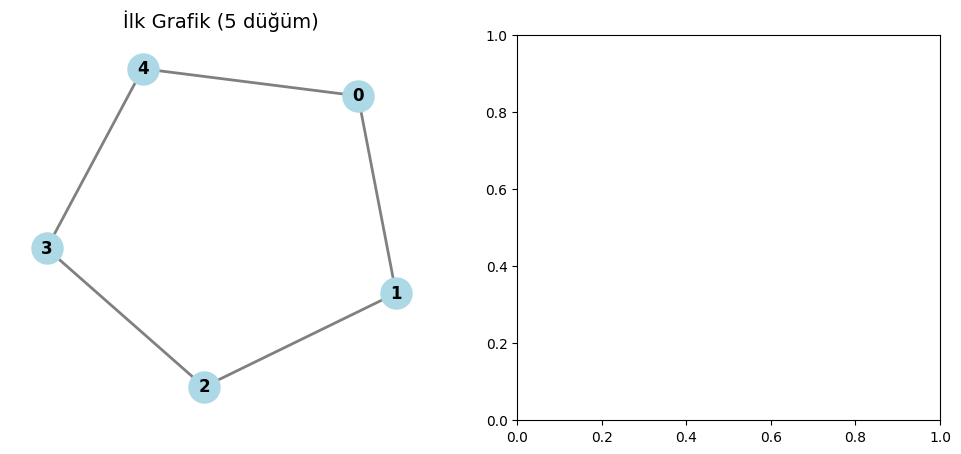

In [37]:
import networkx as nx
import matplotlib.pyplot as plt
G1 = nx.Graph()

# Düğümleri ekle (0'dan 4'e)
G1.add_nodes_from(range(5))

# Kenarları ekle (orijinal edge_index)
edges1 = [(0,1), (1,2), (2,3), (3,4), (0,4)]
G1.add_edges_from(edges1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
pos1 = nx.spring_layout(G1, seed=42)  # sabit düzen
nx.draw_networkx_nodes(G1, pos1, node_color='lightblue', node_size=500, ax=ax1)
nx.draw_networkx_labels(G1, pos1, font_size=12, font_weight='bold', ax=ax1)
nx.draw_networkx_edges(G1, pos1, edge_color='gray', width=2, ax=ax1)
ax1.set_title("İlk Grafik (5 düğüm)", fontsize=14)
ax1.axis('off')

In [40]:
print("Eğitim başlıyor...")
for epoch in range(200):
    loss = train()
    if epoch % 50 == 0:
        print(f"Epoch {epoch:3d} | Loss: {loss:.4f}")

# -------------------------------
# 4. YENİ BİR DÜĞÜM EKLEME (İNDÜKTİF TAHMİN)
# -------------------------------


Eğitim başlıyor...
Epoch   0 | Loss: 1.5130
Epoch  50 | Loss: 1.0435
Epoch 100 | Loss: 1.1516
Epoch 150 | Loss: 1.0050


In [42]:
print("\n--- Yeni düğüm ekleniyor (6. düğüm) ---")
# Yeni düğümün özellikleri (3 boyutlu)
new_node_feat = torch.randn(1, 3)  # 1x3

# Mevcut grafiğe bu yeni düğümü bağlayalım (örneğin 0 ve 2 numaralı düğümlere)
new_edges = torch.tensor([[5, 5], [0, 2]], dtype=torch.long)  # yeni node index=5
updated_edge_index = torch.cat([data.edge_index, new_edges], dim=1)

# Tüm node özelliklerini birleştir (5 eski + 1 yeni)
updated_x = torch.cat([data.x, new_node_feat], dim=0)




--- Yeni düğüm ekleniyor (6. düğüm) ---


In [44]:
print("Yeni  eklenen node sadece feature ı" ,new_node_feat)

Yeni  eklenen node sadece feature ı tensor([[-0.0733,  0.8925, -0.9190]])


In [46]:
# Modeli yeniden eğitmeden sadece forward geçişi yap
model.eval()
with torch.no_grad():
    # Yeni grafik için embedding hesapla
    new_embed = model(updated_x, updated_edge_index)   # shape: 6x8
    
    # Yeni düğümün embedding'i (son satır)
    new_node_emb = new_embed[-1]  # 6. düğüm
    
    # Mevcut tüm düğümlerle (0..4) olan bağlantı olasılıklarını hesapla
    existing_nodes_emb = new_embed[:-1]  # 5x8
    scores = (new_node_emb * existing_nodes_emb).sum(dim=1)   # nokta çarpım
    probs = torch.sigmoid(scores)
    
    print("\nYeni düğümün mevcut düğümlerle etkileşim olasılıkları:")
    for i, p in enumerate(probs):
        print(f"  Düğüm {i} ile: {p.item():.4f}")


Yeni düğümün mevcut düğümlerle etkileşim olasılıkları:
  Düğüm 0 ile: 0.9206
  Düğüm 1 ile: 0.5315
  Düğüm 2 ile: 0.4105
  Düğüm 3 ile: 0.0569
  Düğüm 4 ile: 0.5598


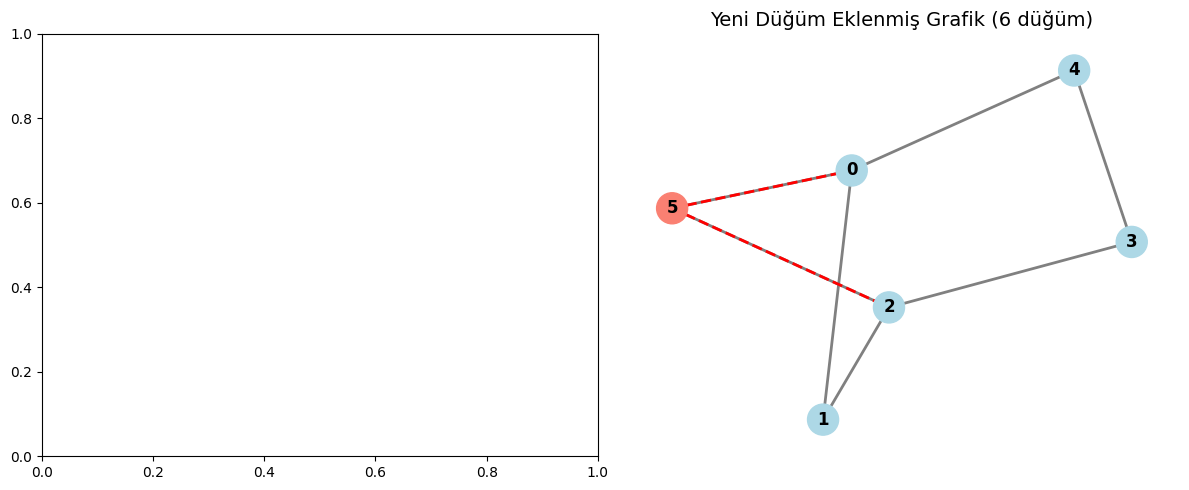

In [52]:
G2 = nx.Graph()

# Eski düğümler + yeni düğüm (5)
G2.add_nodes_from(range(6))

# Eski kenarlar + yeni düğümün bağlantıları (örnek: 5-0 ve 5-2)
edges2 = edges1 + [(5,0), (5,2)]
G2.add_edges_from(edges2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
# İkinci grafik (yeni düğüm)
pos2 = nx.spring_layout(G2, seed=42)  # aynı seed ile benzer düzen
# Yeni düğümü farklı renkte gösterelim
node_colors = ['lightblue'] * 5 + ['salmon']  # 0-4 mavi, 5 kırmızı
nx.draw_networkx_nodes(G2, pos2, node_color=node_colors, node_size=500, ax=ax2)
nx.draw_networkx_labels(G2, pos2, font_size=12, font_weight='bold', ax=ax2)
nx.draw_networkx_edges(G2, pos2, edge_color='gray', width=2, ax=ax2)
# Yeni kenarları farklı renkte gösterelim
new_edges = [(5,0), (5,2)]
nx.draw_networkx_edges(G2, pos2, edgelist=new_edges, edge_color='red', width=2, style='dashed', ax=ax2)
ax2.set_title("Yeni Düğüm Eklenmiş Grafik (6 düğüm)", fontsize=14)
ax2.axis('off')

plt.tight_layout()
plt.show()

In [54]:
print("Düğüm özellikleri (Yeni data.x):")
print(updated_x)  # shape: [num_nodes, num_node_features]

print(f"\nHer düğümdeki özellik sayısı: {updated_x.size(1)}")
print(f"Toplam düğüm sayısı: {updated_x.size(0)}")

# Her bir düğümün özelliklerini ayrı ayrı yazdırmak için
for i in range(updated_x.size(0)):
    print(f"Düğüm {i} özellikleri: {updated_x[i].tolist()}")

Düğüm özellikleri (Yeni data.x):
tensor([[-0.4930, -0.3263,  0.0330],
        [ 0.7762, -0.3658, -1.1477],
        [-1.3111, -1.4996, -0.0021],
        [ 0.0688, -0.2429,  0.1481],
        [ 1.6757,  0.8699, -0.4791],
        [-0.0733,  0.8925, -0.9190]])

Her düğümdeki özellik sayısı: 3
Toplam düğüm sayısı: 6
Düğüm 0 özellikleri: [-0.49304014444351196, -0.3262580931186676, 0.0330130010843277]
Düğüm 1 özellikleri: [0.7761958241462708, -0.36575424671173096, -1.147714376449585]
Düğüm 2 özellikleri: [-1.3111357688903809, -1.4995568990707397, -0.002115195617079735]
Düğüm 3 özellikleri: [0.06878155469894409, -0.24293871223926544, 0.14805176854133606]
Düğüm 4 özellikleri: [1.675694465637207, 0.8698775172233582, -0.47908949851989746]
Düğüm 5 özellikleri: [-0.0733349472284317, 0.8924738168716431, -0.9190460443496704]


In [56]:
# Önceki koddan devamla
print("Düğüm özellikleri (data.x):")
print(data.x)  # shape: [num_nodes, num_node_features]

print(f"\nHer düğümdeki özellik sayısı: {data.num_node_features}")
print(f"Toplam düğüm sayısı: {data.num_nodes}")

# Her bir düğümün özelliklerini ayrı ayrı yazdırmak için
for i in range(data.num_nodes):
    print(f"Düğüm {i} özellikleri: {data.x[i].tolist()}")

Düğüm özellikleri (data.x):
tensor([[-0.4930, -0.3263,  0.0330],
        [ 0.7762, -0.3658, -1.1477],
        [-1.3111, -1.4996, -0.0021],
        [ 0.0688, -0.2429,  0.1481],
        [ 1.6757,  0.8699, -0.4791]])

Her düğümdeki özellik sayısı: 3
Toplam düğüm sayısı: 5
Düğüm 0 özellikleri: [-0.49304014444351196, -0.3262580931186676, 0.0330130010843277]
Düğüm 1 özellikleri: [0.7761958241462708, -0.36575424671173096, -1.147714376449585]
Düğüm 2 özellikleri: [-1.3111357688903809, -1.4995568990707397, -0.002115195617079735]
Düğüm 3 özellikleri: [0.06878155469894409, -0.24293871223926544, 0.14805176854133606]
Düğüm 4 özellikleri: [1.675694465637207, 0.8698775172233582, -0.47908949851989746]


#  Graph-in-Graph (GiG) örneği

In [25]:


# -------------------------------
# 1. SENTETİK VERİ OLUŞTURMA (Hibrit Yaklaşım)
# -------------------------------
# --- Transdüktif Katman: 5 düğüm (3 ilaç, 2 hedef) ve aralarındaki bilinen etkileşimler
num_drugs = 3
num_targets = 2
num_nodes = num_drugs + num_targets

# Bilinen etkileşim matrisi (y=1: etkileşim var, y=0: yok)
# Bu veri, daha önceki örneklerdeki gibi modele gösterilecek.
interaction_matrix = torch.tensor([
    [1, 0],  # Drug 0, Target 0 ile etkileşir, Target 1 ile etkileşmez
    [1, 1],  # Drug 1, her iki hedefle de etkileşir
    [0, 1]   # Drug 2, Target 0 ile etkileşmez, Target 1 ile etkileşir 3 e 2 lik matris 0 1 2 ile 0 1 arasında adjend matrix yani bi partial ağ
], dtype=torch.float32)

# --- İndüktif Katman: Her ilaç ve hedef için, onları tanımlayan özellik vektörleri (features)
# Bu özellikler, moleküler yapıyı temsil eder ve modelin yeni ilaçları tanımasını sağlar.
drug_features = torch.randn(num_drugs, 4)   # Her ilaç için 4 özellik
target_features = torch.randn(num_targets, 4) # Her hedef için 4 özellik

print("İlaç Özellikleri (Drug Features):")
print(drug_features)
print("\nHedef Özellikleri (Target Features):")
print(target_features)
print("\nBilinen Etkileşim Matrisi (Interaction Matrix):")
print(interaction_matrix)



İlaç Özellikleri (Drug Features):
tensor([[-0.0951,  0.4459,  0.7037, -2.2778],
        [ 0.5035, -0.7168,  0.4109, -0.1440],
        [ 0.2895,  0.4092,  0.7751, -1.9763]])

Hedef Özellikleri (Target Features):
tensor([[ 0.6952, -0.9631,  1.0347, -0.3247],
        [ 0.1195,  1.0736,  0.6453,  1.2574]])

Bilinen Etkileşim Matrisi (Interaction Matrix):
tensor([[1., 0.],
        [1., 1.],
        [0., 1.]])


In [28]:
# -------------------------------
# 2. HİBRİT MODEL (Transdüktif + İndüktif)
# -------------------------------
class HybridDTIModel(nn.Module):
    def __init__(self, feature_dim, hidden_dim):
        super().__init__()
        # İndüktif Katman: İlaç ve hedef özelliklerini işleyen MLP
        self.drug_encoder = nn.Sequential(
            nn.Linear(feature_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim)
        )
        self.target_encoder = nn.Sequential(
            nn.Linear(feature_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim)
        )
        
        # Transdüktif Katman: Etkileşim tahmini için MLP
        self.predictor = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1),
            nn.Sigmoid()
        )
    
    def forward(self, drug_feat, target_feat, drug_idx, target_idx):
        # 1. İndüktif Adım: İlaç ve hedef özelliklerinden embedding'ler oluştur
        drug_emb = self.drug_encoder(drug_feat)   # shape: [num_drugs, hidden_dim]
        target_emb = self.target_encoder(target_feat) # shape: [num_targets, hidden_dim]
        
        # 2. Transdüktif Adım: İstenen (drug_idx, target_idx) çifti için embedding'leri birleştir ve etkileşim olasılığını hesapla
        batch_drug_emb = drug_emb[drug_idx]
        batch_target_emb = target_emb[target_idx]
        combined = torch.cat([batch_drug_emb, batch_target_emb], dim=1)
        return self.predictor(combined).squeeze()



In [31]:
# Model parametreleri
feature_dim = 4
hidden_dim = 8
model = HybridDTIModel(feature_dim, hidden_dim)
optimizer = optim.Adam(model.parameters(), lr=0.01)
criterion = nn.BCELoss()

# -------------------------------
# 3. EĞİTİM (Transdüktif Öğrenme)
# -------------------------------
# Eğitim için kullanılacak ilaç-hedef çiftlerini ve etiketlerini hazırlayalım
train_pairs = []
train_labels = []
for i in range(num_drugs):
    for j in range(num_targets):
        train_pairs.append((i, j))
        train_labels.append(interaction_matrix[i, j])

train_pairs = torch.tensor(train_pairs)
train_labels = torch.tensor(train_labels)

print("\nEğitim başlıyor...")
for epoch in range(500):
    model.train()
    optimizer.zero_grad()
    
    # Modelin tüm eğitim çiftleri için tahmin yapmasını sağla
    predictions = model(drug_features, target_features, 
                        train_pairs[:, 0], train_pairs[:, 1])
    
    loss = criterion(predictions, train_labels)
    loss.backward()
    optimizer.step()
    
    if epoch % 100 == 0:
        print(f"Epoch {epoch:3d} | Loss: {loss.item():.4f}")

# -------------------------------
# 4. DEĞERLENDİRME (Transdüktif Tahmin)
# -------------------------------



Eğitim başlıyor...
Epoch   0 | Loss: 0.7124
Epoch 100 | Loss: 0.1536
Epoch 200 | Loss: 0.0627
Epoch 300 | Loss: 0.0360
Epoch 400 | Loss: 0.0238


In [33]:
# Eğitim tamamlandıktan sonra modelin tüm olası çiftler için tahminlerini alalım
model.eval()
with torch.no_grad():
    all_predictions = []
    for i in range(num_drugs):
        row = []
        for j in range(num_targets):
            pred = model(drug_features, target_features, 
                        torch.tensor([i]), torch.tensor([j]))
            row.append(pred.item())
        all_predictions.append(row)
    
    print("\nModelin Tahmin Ettiği Etkileşim Matrisi:")
    for row in all_predictions:
        print([f"{x:.3f}" for x in row])
    
    print("\nGerçek Etkileşim Matrisi:")
    print(interaction_matrix.numpy())




Modelin Tahmin Ettiği Etkileşim Matrisi:
['1.000', '0.050']
['1.000', '1.000']
['0.050', '1.000']

Gerçek Etkileşim Matrisi:
[[1. 0.]
 [1. 1.]
 [0. 1.]]


In [35]:
# -------------------------------
# 5. YENİ BİR İLAÇ EKLEME (İndüktif Tahmin)
# -------------------------------
# Bu adım, hibrit modelin en güçlü yanını gösterir. Eğitilmiş model, yeni bir ilaç geldiğinde,
# sadece onun özellik vektörünü kullanarak, diğer ilaçlarla benzerliğine veya etkileşimine bakmadan,
# doğrudan tahmin yapabilir.
print("\n--- Yeni İlaç Ekleniyor (İndüktif Tahmin) ---")
# Yeni ilaç için rastgele bir feature vektörü oluşturalım
new_drug_features = torch.randn(1, feature_dim)

# Yeni ilacın mevcut hedeflerle etkileşim olasılıklarını hesapla
new_predictions = []
for j in range(num_targets):
    pred = model(new_drug_features, target_features, 
                torch.tensor([0]), torch.tensor([j]))
    new_predictions.append(pred.item())

print(f"Yeni ilacın hedef {0} ile etkileşim olasılığı: {new_predictions[0]:.4f}")
print(f"Yeni ilacın hedef {1} ile etkileşim olasılığı: {new_predictions[1]:.4f}")


--- Yeni İlaç Ekleniyor (İndüktif Tahmin) ---
Yeni ilacın hedef 0 ile etkileşim olasılığı: 0.9295
Yeni ilacın hedef 1 ile etkileşim olasılığı: 1.0000


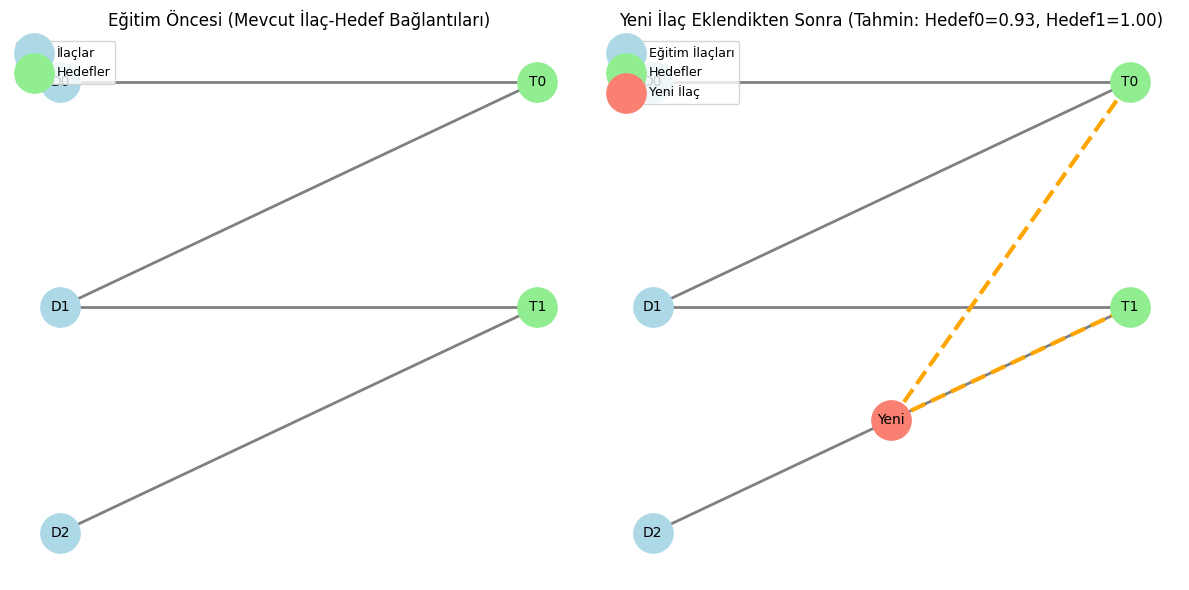

In [44]:
import networkx as nx
import matplotlib.pyplot as plt
import torch

# Varsayalım ki aşağıdaki değişkenler zaten tanımlı (eğitim kodunuzdan geliyor)
# interaction_matrix = 3x2 tensor
# new_predictions = [prob_target0, prob_target1]

# Örnek değerler (eğer kodunuz çalıştırılmadıysa tanımlayın)
if 'interaction_matrix' not in dir():
    interaction_matrix = torch.tensor([[1,0],[1,1],[0,1]], dtype=torch.float32)
if 'new_predictions' not in dir():
    new_predictions = [0.92, 0.14]

num_drugs = interaction_matrix.shape[0]   # 3
num_targets = interaction_matrix.shape[1] # 2

# Düğüm indeksleri: ilaçlar = 0..num_drugs-1, hedefler = num_drugs .. num_drugs+num_targets-1
target_start = num_drugs
drug_nodes = list(range(num_drugs))
target_nodes = list(range(target_start, target_start + num_targets))

# Eğitim kenarları (gerçek etkileşimler)
train_edges = []
for i in range(num_drugs):
    for j in range(num_targets):
        if interaction_matrix[i, j] == 1:
            train_edges.append((i, target_start + j))

# ---- 1. Eğitim öncesi grafik (mevcut ilaçlar ve hedefler) ----
G_before = nx.Graph()
G_before.add_nodes_from(drug_nodes, layer='drug')
G_before.add_nodes_from(target_nodes, layer='target')
G_before.add_edges_from(train_edges)

# Konumlandırma: ilaçlar sol, hedefler sağ (dikey hizalama)
pos_before = {}
for i, node in enumerate(drug_nodes):
    pos_before[node] = (0, -i)          # x=0, y=0,-1,-2
for i, node in enumerate(target_nodes):
    pos_before[node] = (2, -i)          # x=2, y=0,-1

# ---- 2. Yeni ilaç eklendikten sonraki grafik ----
new_drug_node = num_drugs + num_targets   # 3+2=5
G_after = nx.Graph()
G_after.add_nodes_from(drug_nodes, layer='drug')
G_after.add_nodes_from(target_nodes, layer='target')
G_after.add_node(new_drug_node, layer='new_drug')
G_after.add_edges_from(train_edges)

# Tahmin edilen kenarlar (olasılık > 0.5)
pred_edges = []
for j, prob in enumerate(new_predictions):
    if prob > 0.5:
        pred_edges.append((new_drug_node, target_start + j))
G_after.add_edges_from(pred_edges)

# Konumlandırma: mevcut ilaçlar sol, hedefler sağ, yeni ilaç ortada altta
pos_after = {}
for i, node in enumerate(drug_nodes):
    pos_after[node] = (0, -i)
for i, node in enumerate(target_nodes):
    pos_after[node] = (2, -i)
pos_after[new_drug_node] = (1, -1.5)   # ortada, biraz aşağıda

# ---- Çizim (yan yana) ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

# Sol grafik: eğitim öncesi
nx.draw_networkx_nodes(G_before, pos_before, nodelist=drug_nodes, node_color='lightblue', node_size=800, ax=ax1, label='İlaçlar')
nx.draw_networkx_nodes(G_before, pos_before, nodelist=target_nodes, node_color='lightgreen', node_size=800, ax=ax1, label='Hedefler')
nx.draw_networkx_edges(G_before, pos_before, edgelist=train_edges, edge_color='gray', width=2, ax=ax1)
nx.draw_networkx_labels(G_before, pos_before, 
                        labels={**{i:f'D{i}' for i in drug_nodes}, **{i:f'T{i-target_start}' for i in target_nodes}}, 
                        font_size=10, ax=ax1)
ax1.set_title("Eğitim Öncesi (Mevcut İlaç-Hedef Bağlantıları)", fontsize=12)
ax1.axis('off')
ax1.legend(loc='upper left', fontsize=9)

# Sağ grafik: yeni ilaç eklendikten sonra
nx.draw_networkx_nodes(G_after, pos_after, nodelist=drug_nodes, node_color='lightblue', node_size=800, ax=ax2, label='Eğitim İlaçları')
nx.draw_networkx_nodes(G_after, pos_after, nodelist=target_nodes, node_color='lightgreen', node_size=800, ax=ax2, label='Hedefler')
nx.draw_networkx_nodes(G_after, pos_after, nodelist=[new_drug_node], node_color='salmon', node_size=800, ax=ax2, label='Yeni İlaç')
nx.draw_networkx_edges(G_after, pos_after, edgelist=train_edges, edge_color='gray', width=2, ax=ax2)
if pred_edges:
    nx.draw_networkx_edges(G_after, pos_after, edgelist=pred_edges, edge_color='orange', width=3, style='dashed', ax=ax2)
nx.draw_networkx_labels(G_after, pos_after, 
                        labels={**{i:f'D{i}' for i in drug_nodes}, 
                                **{i:f'T{i-target_start}' for i in target_nodes},
                                new_drug_node:'Yeni'}, 
                        font_size=10, ax=ax2)
ax2.set_title(f"Yeni İlaç Eklendikten Sonra (Tahmin: Hedef0={new_predictions[0]:.2f}, Hedef1={new_predictions[1]:.2f})", fontsize=12)
ax2.axis('off')
ax2.legend(loc='upper left', fontsize=9)

plt.tight_layout()
plt.show()


# farklı feature boyutlu 


In [46]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np

# -------------------------------
# 1. SENTETİK VERİ: FARKLI BOYUTLARDA ÖZELLİKLER
# -------------------------------
num_drugs = 3 # 0,1,2
num_targets = 2 # 3,4

# İlaç özellikleri: 2048 boyutlu (örneğin kimyasal parmak izi)
drug_feat_dim = 2048
drug_features = torch.randn(num_drugs, drug_feat_dim)

# Hedef özellikleri: 1024 boyutlu (örneğin protein dizisi embedding'i)
target_feat_dim = 1024
target_features = torch.randn(num_targets, target_feat_dim)

# Bilinen etkileşim matrisi (3 ilaç x 2 hedef)
interaction_matrix = torch.tensor([
    [1, 0],
    [1, 1],
    [0, 1]
], dtype=torch.float32)

print("İlaç özellik boyutu:", drug_features.shape)   # [3, 2048]
print("Hedef özellik boyutu:", target_features.shape) # [2, 1024]

# -------------------------------
# 2. HİBRİT MODEL (FARKLI BOYUTLAR İÇİN)
# -------------------------------
class HybridDTIModel(nn.Module):
    def __init__(self, drug_feat_dim, target_feat_dim, hidden_dim=128, embedding_dim=64):
        super().__init__()
        # İlaç encoder: 2048 -> hidden -> embedding
        self.drug_encoder = nn.Sequential(
            nn.Linear(drug_feat_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, embedding_dim)
        )
        # Hedef encoder: 1024 -> hidden -> embedding
        self.target_encoder = nn.Sequential(
            nn.Linear(target_feat_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, embedding_dim)
        )
        # Etkileşim tahmincisi: iki embedding'i birleştir (2*embedding_dim) -> 1
        self.predictor = nn.Sequential(
            nn.Linear(embedding_dim * 2, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1),
            nn.Sigmoid()
        )
    
    def forward(self, drug_feat, target_feat, drug_idx, target_idx):
        # Tüm ilaç ve hedeflerin embedding'lerini hesapla
        drug_emb = self.drug_encoder(drug_feat)   # [num_drugs, embedding_dim]
        target_emb = self.target_encoder(target_feat) # [num_targets, embedding_dim]
        
        # İstenen çiftlerin embedding'lerini al
        batch_drug_emb = drug_emb[drug_idx]
        batch_target_emb = target_emb[target_idx]
        
        # Birleştir ve tahmin yap
        combined = torch.cat([batch_drug_emb, batch_target_emb], dim=1)
        return self.predictor(combined).squeeze()

# Model oluştur
model = HybridDTIModel(drug_feat_dim, target_feat_dim, hidden_dim=128, embedding_dim=64)
optimizer = optim.Adam(model.parameters(), lr=0.001)
criterion = nn.BCELoss()

# Eğitim için tüm olası çiftler (3x2=6)
train_pairs = []
train_labels = []
for i in range(num_drugs):
    for j in range(num_targets):
        train_pairs.append((i, j))
        train_labels.append(interaction_matrix[i, j])

train_pairs = torch.tensor(train_pairs)
train_labels = torch.tensor(train_labels)

# -------------------------------
# 3. EĞİTİM
# -------------------------------
print("\nEğitim başlıyor...")
for epoch in range(300):
    model.train()
    optimizer.zero_grad()
    
    predictions = model(drug_features, target_features,
                        train_pairs[:, 0], train_pairs[:, 1])
    loss = criterion(predictions, train_labels)
    loss.backward()
    optimizer.step()
    
    if epoch % 100 == 0:
        print(f"Epoch {epoch:3d} | Loss: {loss.item():.4f}")

# -------------------------------
# 4. DEĞERLENDİRME (Transdüktif)
# -------------------------------
model.eval()
with torch.no_grad():
    print("\nTahmin edilen etkileşim matrisi (olasılıklar):")
    for i in range(num_drugs):
        row = []
        for j in range(num_targets):
            pred = model(drug_features, target_features,
                         torch.tensor([i]), torch.tensor([j]))
            row.append(f"{pred.item():.3f}")
        print(row)
    
    print("\nGerçek matris:")
    print(interaction_matrix.numpy())

# -------------------------------
# 5. YENİ BİR İLAÇ (İndüktif) - FARKLI BOYUTTA ÖZELLİK
# -------------------------------
print("\n--- Yeni ilaç ekleniyor (2048 boyutlu özellik) ---")
new_drug_feat = torch.randn(1, drug_feat_dim)  # aynı boyutta # yeni eklene node  ilaç 
new_predictions = []
for j in range(num_targets):
    pred = model(new_drug_feat, target_features,
                 torch.tensor([0]), torch.tensor([j]))
    new_predictions.append(pred.item())
print(f"Yeni ilacın hedef0 olasılığı: {new_predictions[0]:.4f}")
print(f"Yeni ilacın hedef1 olasılığı: {new_predictions[1]:.4f}")

İlaç özellik boyutu: torch.Size([3, 2048])
Hedef özellik boyutu: torch.Size([2, 1024])

Eğitim başlıyor...
Epoch   0 | Loss: 0.6710
Epoch 100 | Loss: 0.0000
Epoch 200 | Loss: 0.0000

Tahmin edilen etkileşim matrisi (olasılıklar):
['1.000', '0.000']
['1.000', '1.000']
['0.000', '1.000']

Gerçek matris:
[[1. 0.]
 [1. 1.]
 [0. 1.]]

--- Yeni ilaç ekleniyor (2048 boyutlu özellik) ---
Yeni ilacın hedef0 olasılığı: 0.9700
Yeni ilacın hedef1 olasılığı: 0.9995


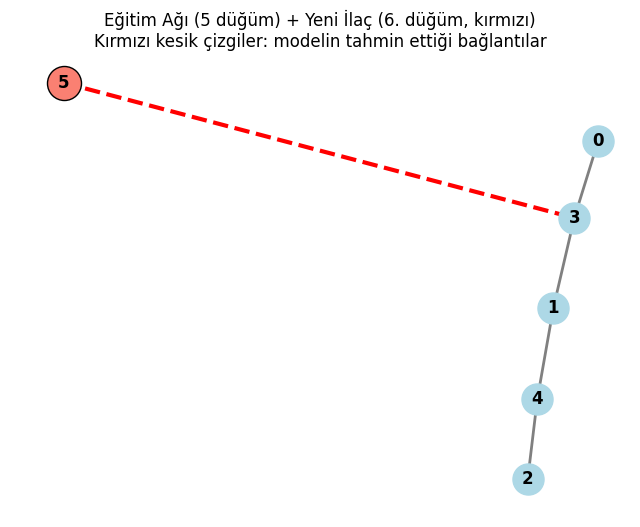

In [48]:
import networkx as nx
import matplotlib.pyplot as plt
import torch

# Önceki kodda üretilen tahminler (new_predictions) kullanılacak.
# Burada örnek değerlerle devam ediyorum, siz kendi çıktınızla değiştirebilirsiniz.
# Diyelim ki model şu olasılıkları üretti:
new_predictions = [0.92, 0.14]  # hedef0 için 0.92, hedef1 için 0.14

# Düğümler: 0,1,2 = ilaçlar; 3,4 = hedefler; 5 = yeni ilaç
G = nx.Graph()
G.add_nodes_from([0,1,2,3,4,5])

# Bilinen eğitim kenarları (interaction_matrix'teki 1'ler)
# Drug0-Target0, Drug1-Target0, Drug1-Target1, Drug2-Target1
train_edges = [(0,3), (1,3), (1,4), (2,4)]
G.add_edges_from(train_edges)

# Modelin tahmin ettiği yüksek olasılıklı kenarlar (eşik 0.5)
pred_edges = []
if new_predictions[0] > 0.5:
    pred_edges.append((5,3))   # yeni ilaç -> hedef0
if new_predictions[1] > 0.5:
    pred_edges.append((5,4))   # yeni ilaç -> hedef1

# Çizim
pos = nx.spring_layout(G, seed=42)
plt.figure(figsize=(8,6))

# Düğümleri çiz (yeni düğümü farklı renkte)
nx.draw_networkx_nodes(G, pos, nodelist=[0,1,2,3,4], node_color='lightblue', node_size=500)
nx.draw_networkx_nodes(G, pos, nodelist=[5], node_color='salmon', node_size=600, edgecolors='black')
nx.draw_networkx_labels(G, pos, font_size=12, font_weight='bold')

# Eğitim kenarları (gri)
nx.draw_networkx_edges(G, pos, edgelist=train_edges, edge_color='gray', width=2)
# Tahmin edilen kenarlar (kırmızı kesik)
if pred_edges:
    nx.draw_networkx_edges(G, pos, edgelist=pred_edges, edge_color='red', width=3, style='dashed')

plt.title("Eğitim Ağı (5 düğüm) + Yeni İlaç (6. düğüm, kırmızı)\nKırmızı kesik çizgiler: modelin tahmin ettiği bağlantılar", fontsize=12)
plt.axis('off')
plt.show()

Eğitim başlıyor...
Epoch 0 | Loss: 0.6816
Epoch 100 | Loss: 0.0000
Epoch 200 | Loss: 0.0000

--- Modelin Tahmin Ettiği 4x2 Etkileşim Matrisi ---
Drug 0: ['1.000', '0.000']
Drug 1: ['1.000', '1.000']
Drug 2: ['0.000', '1.000']
Drug 3: ['0.817', '0.956']

--- Gerçek (Eğitimde Bilinen) 3x2 Matris ---
[[1. 0.]
 [1. 1.]
 [0. 1.]]
Yeni ilaç (Drug 3) için gerçek etkileşim bilinmiyor (model tahmini).


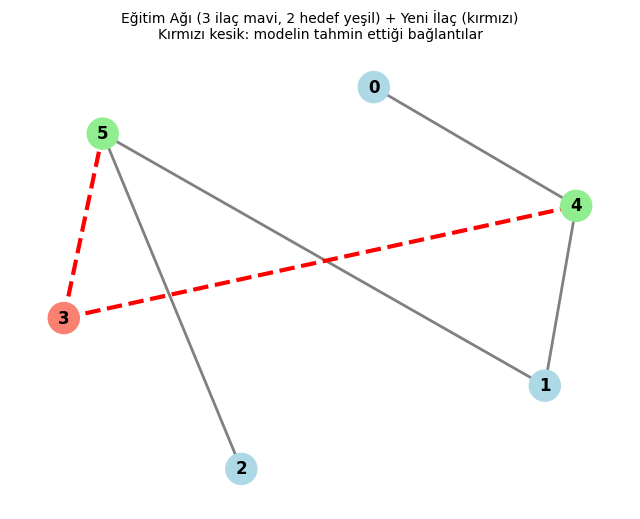

In [50]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

# -------------------------------
# 1. VERİ: 3 ilaç (eğitim) + 1 yeni ilaç (test)
# -------------------------------
num_drugs_train = 3
num_targets = 2
drug_feat_dim = 2048
target_feat_dim = 1024

# Eğitim ilaçları ve hedefler için özellikler
drug_features_train = torch.randn(num_drugs_train, drug_feat_dim)
target_features = torch.randn(num_targets, target_feat_dim)

# Bilinen etkileşim matrisi (3x2)
interaction_matrix_train = torch.tensor([
    [1, 0],
    [1, 1],
    [0, 1]
], dtype=torch.float32)

# -------------------------------
# 2. HİBRİT MODEL (aynı)
# -------------------------------
class HybridDTIModel(nn.Module):
    def __init__(self, drug_feat_dim, target_feat_dim, hidden_dim=128, embedding_dim=64):
        super().__init__()
        self.drug_encoder = nn.Sequential(
            nn.Linear(drug_feat_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, embedding_dim)
        )
        self.target_encoder = nn.Sequential(
            nn.Linear(target_feat_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, embedding_dim)
        )
        self.predictor = nn.Sequential(
            nn.Linear(embedding_dim * 2, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1),
            nn.Sigmoid()
        )
    
    def forward(self, drug_feat, target_feat, drug_idx, target_idx):
        drug_emb = self.drug_encoder(drug_feat)
        target_emb = self.target_encoder(target_feat)
        batch_drug_emb = drug_emb[drug_idx]
        batch_target_emb = target_emb[target_idx]
        combined = torch.cat([batch_drug_emb, batch_target_emb], dim=1)
        return self.predictor(combined).squeeze()

model = HybridDTIModel(drug_feat_dim, target_feat_dim)
optimizer = optim.Adam(model.parameters(), lr=0.001)
criterion = nn.BCELoss()

# Eğitim çiftleri (3x2=6)
train_pairs = []
train_labels = []
for i in range(num_drugs_train):
    for j in range(num_targets):
        train_pairs.append((i, j))
        train_labels.append(interaction_matrix_train[i, j])
train_pairs = torch.tensor(train_pairs)
train_labels = torch.tensor(train_labels)

# Eğitim
print("Eğitim başlıyor...")
for epoch in range(300):
    model.train()
    optimizer.zero_grad()
    preds = model(drug_features_train, target_features, train_pairs[:,0], train_pairs[:,1])
    loss = criterion(preds, train_labels)
    loss.backward()
    optimizer.step()
    if epoch % 100 == 0:
        print(f"Epoch {epoch} | Loss: {loss.item():.4f}")

# -------------------------------
# 3. YENİ İLAÇ EKLE (4. ilaç)
# -------------------------------
new_drug_features = torch.randn(1, drug_feat_dim)  # 1x2048
# Tüm ilaç özelliklerini birleştir (3 eğitim + 1 yeni)
all_drug_features = torch.cat([drug_features_train, new_drug_features], dim=0)  # 4x2048

# Modelin tüm 4 ilaç için embedding'lerini hesapla (forward sırasında otomatik)
model.eval()
with torch.no_grad():
    # Yeni ilacın hedef tahminleri (1x2)
    new_predictions = []
    for j in range(num_targets):
        pred = model(new_drug_features, target_features, torch.tensor([0]), torch.tensor([j]))
        new_predictions.append(pred.item())
    
    # Eğitim ilaçlarının tahminleri (3x2) - zaten eğitimden biliyoruz, ama modelin çıktısını alalım
    train_predictions = []
    for i in range(num_drugs_train):
        row = []
        for j in range(num_targets):
            pred = model(drug_features_train, target_features, torch.tensor([i]), torch.tensor([j]))
            row.append(pred.item())
        train_predictions.append(row)
    
    # Birleştirilmiş 4x2 matris
    full_prediction_matrix = train_predictions + [new_predictions]

print("\n--- Modelin Tahmin Ettiği 4x2 Etkileşim Matrisi ---")
for i, row in enumerate(full_prediction_matrix):
    print(f"Drug {i}: {[f'{x:.3f}' for x in row]}")

print("\n--- Gerçek (Eğitimde Bilinen) 3x2 Matris ---")
print(interaction_matrix_train.numpy())
print("Yeni ilaç (Drug 3) için gerçek etkileşim bilinmiyor (model tahmini).")

# -------------------------------
# 4. GRAFİK ÇİZİMİ (6 düğüm: 4 ilaç + 2 hedef)
# -------------------------------
G = nx.Graph()
# Düğümler: 0,1,2,3 = ilaçlar (3 eğitim, 3 yeni), 4,5 = hedefler
G.add_nodes_from([0,1,2,3,4,5])

# Eğitim kenarları (gerçek etkileşimler)
train_edges = []
for i in range(num_drugs_train):
    for j in range(num_targets):
        if interaction_matrix_train[i, j] == 1:
            train_edges.append((i, 4+j))  # hedef düğüm indexleri 4,5

# Modelin tahmin ettiği yüksek olasılıklı kenarlar (eşik 0.5) - yeni ilaç için
pred_edges = []
if new_predictions[0] > 0.5:
    pred_edges.append((3, 4))
if new_predictions[1] > 0.5:
    pred_edges.append((3, 5))

# Tüm kenarlar (eğitim + tahmin)
all_edges = train_edges + pred_edges

pos = nx.spring_layout(G, seed=42)
plt.figure(figsize=(8,6))
# Düğüm renkleri: eğitim ilaçları mavi, yeni ilaç kırmızı, hedefler yeşil
node_colors = []
for node in G.nodes():
    if node in [0,1,2]:
        node_colors.append('lightblue')
    elif node == 3:
        node_colors.append('salmon')
    else:
        node_colors.append('lightgreen')
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=500)
nx.draw_networkx_labels(G, pos, font_size=12, font_weight='bold')
nx.draw_networkx_edges(G, pos, edgelist=train_edges, edge_color='gray', width=2)
if pred_edges:
    nx.draw_networkx_edges(G, pos, edgelist=pred_edges, edge_color='red', width=3, style='dashed')
plt.title("Eğitim Ağı (3 ilaç mavi, 2 hedef yeşil) + Yeni İlaç (kırmızı)\nKırmızı kesik: modelin tahmin ettiği bağlantılar", fontsize=10)
plt.axis('off')
plt.show()

# Bağlantıyı kurup feature tahmin etme 

In [ ]:
# ağı inşa ettikten sonra eğer ideal feature setine ulşatı isen belirli test seti için feature tahmini valide etmek lazım.

In [52]:


# -------------------------------
# 1. SENTETİK VERİ: 5 düğüm, her biri 3 özellik, ancak bazı özellikler eksik
# -------------------------------
num_nodes = 5
full_features = torch.randn(num_nodes, 3)  # gerçek özellikler (bilinmeyen)

# Kenar listesi (bağlantılar) – bu biliniyor
edges = torch.tensor([[0,1], [1,2], [2,3], [3,4], [0,4], [1,3]], dtype=torch.long).t()

# Özelliklerin bir kısmını eksik bırakalım (örneğin düğüm 2'nin tüm özellikleri bilinmiyor)
# Mask: True ise özellik biliniyor, False ise eksik
feature_mask = torch.ones(num_nodes, 3, dtype=torch.bool)
feature_mask[2, :] = False  # 2. düğümün tüm özelliklerini eksik yap

# Bilinen özellikler (eksik yerlerde 0 veya rastgele değer olabilir)
known_features = full_features.clone()
known_features[~feature_mask] = 0  # eksik olanları 0 ile doldur

print("Gerçek özellikler (tümü):")
print(full_features)
print("\nBilinen özellikler (eksikler 0):")
print(known_features)
print("\nEksik düğüm: 2")

# -------------------------------


Gerçek özellikler (tümü):
tensor([[-0.7397,  0.1949, -1.3173],
        [ 0.6458,  0.4965, -0.0881],
        [-2.2016,  0.7598,  0.7104],
        [-0.8233, -1.2873, -1.7250],
        [-1.3476, -1.2857, -0.1677]])

Bilinen özellikler (eksikler 0):
tensor([[-0.7397,  0.1949, -1.3173],
        [ 0.6458,  0.4965, -0.0881],
        [ 0.0000,  0.0000,  0.0000],
        [-0.8233, -1.2873, -1.7250],
        [-1.3476, -1.2857, -0.1677]])

Eksik düğüm: 2


In [54]:
# 2. MODEL: GNN ile düğüm özelliklerini tahmin etme
# -------------------------------
class FeaturePredictorGNN(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super().__init__()
        self.conv1 = nn.Linear(input_dim, hidden_dim)  # basit bir GNN yerine MLP, ama mesajlaşma için graph işlemi yapacağız
        self.conv2 = nn.Linear(hidden_dim, output_dim)
    
    def forward(self, x, edge_index):
        # Basit bir mesaj geçirme: her düğüm, komşularının ortalamasını alır
        num_nodes = x.size(0)
        # Komşuluk matrisi oluştur (basit)
        adj = torch.zeros(num_nodes, num_nodes)
        adj[edge_index[0], edge_index[1]] = 1
        adj[edge_index[1], edge_index[0]] = 1
        # Her düğümün komşularının ortalaması
        neighbor_sum = adj @ x
        degree = adj.sum(dim=1, keepdim=True).clamp(min=1)
        neighbor_avg = neighbor_sum / degree
        # Kendi özellikleri ve komşu ortalamasını birleştir
        combined = torch.cat([x, neighbor_avg], dim=1)
        h = torch.relu(self.conv1(combined))
        out = self.conv2(h)
        return out

model = FeaturePredictorGNN(input_dim=6, hidden_dim=16, output_dim=3)  # input: 3 (kendi) + 3 (komşu ort)
optimizer = optim.Adam(model.parameters(), lr=0.01)
criterion = nn.MSELoss()



In [57]:
# -------------------------------
# 3. EĞİTİM: Sadece bilinen özellikler üzerinden kayıp hesapla
# -------------------------------
# Eğitim sırasında sadece feature_mask'i True olan düğümlerin tahminlerini gerçekle karşılaştır
def train():
    model.train()
    optimizer.zero_grad()
    # Tüm düğümler için özellik tahmini yap
    pred_features = model(known_features, edges)
    # Sadece bilinen özellikler için loss hesapla
    loss = criterion(pred_features[feature_mask], full_features[feature_mask])
    loss.backward()
    optimizer.step()
    return loss.item()




Eğitim başlıyor (eksik özellikleri tahmin etmek için)...
Epoch   0 | Loss: 1.147760
Epoch 100 | Loss: 0.000054
Epoch 200 | Loss: 0.000000
Epoch 300 | Loss: 0.000000
Epoch 400 | Loss: 0.000000

Tahmin edilen tüm özellikler:
tensor([[-0.7397,  0.1949, -1.3173],
        [ 0.6458,  0.4965, -0.0881],
        [-0.0886, -0.0765, -0.1016],
        [-0.8233, -1.2873, -1.7250],
        [-1.3476, -1.2857, -0.1677]])

Eksik düğüm (2) için tahmin edilen özellikler:
tensor([-0.0886, -0.0765, -0.1016])
Gerçek özellikler (2. düğüm):
tensor([-2.2016,  0.7598,  0.7104])


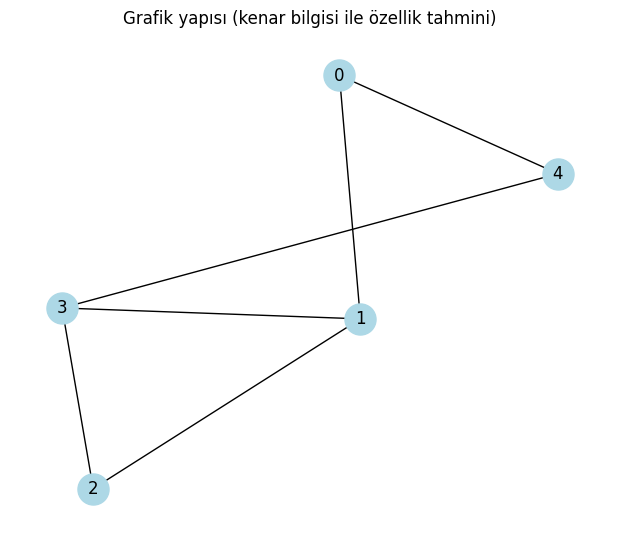

In [60]:
print("\nEğitim başlıyor (eksik özellikleri tahmin etmek için)...")
for epoch in range(500):
    loss = train()
    if epoch % 100 == 0:
        print(f"Epoch {epoch:3d} | Loss: {loss:.6f}")

# -------------------------------
# 4. TAHMİN: Eksik düğümün özelliklerini al
# -------------------------------
model.eval()
with torch.no_grad():
    pred_features = model(known_features, edges)
    print("\nTahmin edilen tüm özellikler:")
    print(pred_features)
    print("\nEksik düğüm (2) için tahmin edilen özellikler:")
    print(pred_features[2])
    print("Gerçek özellikler (2. düğüm):")
    print(full_features[2])

# -------------------------------
# 5. GÖRSELLEŞTİRME (isteğe bağlı)
# -------------------------------
G = nx.Graph()
G.add_nodes_from(range(num_nodes))
G.add_edges_from(edges.t().tolist())
pos = nx.spring_layout(G, seed=42)
plt.figure(figsize=(6,5))
nx.draw(G, pos, with_labels=True, node_color='lightblue', node_size=500)
plt.title("Grafik yapısı (kenar bilgisi ile özellik tahmini)")
plt.show()

İlk durum (mevcut kenarlar):
Düğüm 2'nin tahmin edilen özellikleri (başlangıç): [-0.3321997821331024, -0.07759717106819153, 0.018757954239845276]
Gerçek özellikleri: [-2.0210564136505127, 2.1986794471740723, -1.208014726638794]

Yeni kenar eklendi: (2,4)
İkinci durum (yeni kenar ile):
Düğüm 2'nin tahmin edilen özellikleri (güncel): [-0.19032898545265198, -0.14356276392936707, 0.00651618093252182]
Gerçek özellikleri: [-2.0210564136505127, 2.1986794471740723, -1.208014726638794]


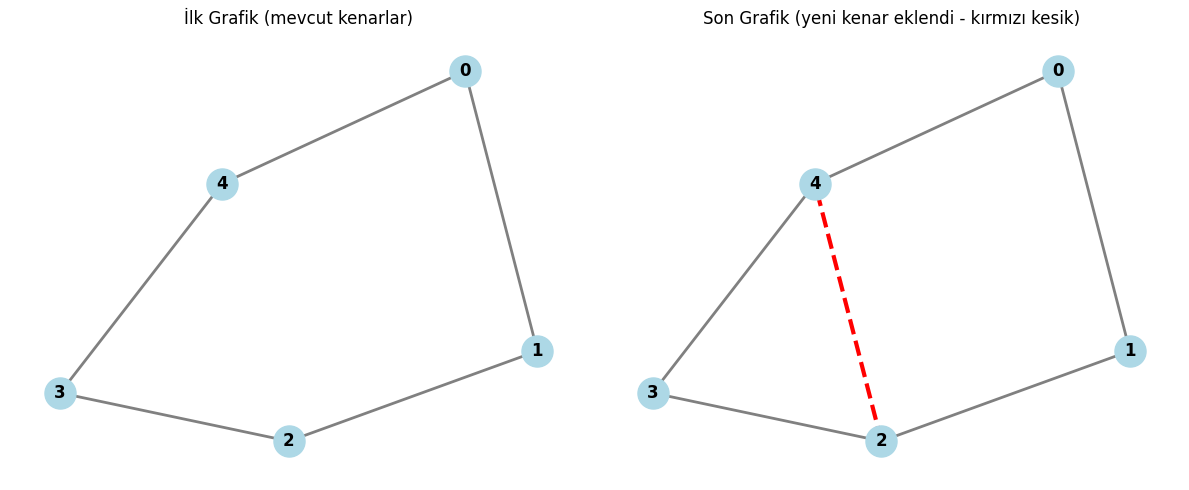

In [63]:
import torch
import torch.nn as nn
import torch.optim as optim
import networkx as nx
import matplotlib.pyplot as plt

# -------------------------------
# 1. BAŞLANGIÇ GRAFİĞİ (5 düğüm, mevcut kenarlar)
# -------------------------------
num_nodes = 5
# Gerçek özellikler (tüm düğümlerin)
full_features = torch.randn(num_nodes, 3)

# Mevcut kenarlar (başlangıç)
initial_edges = torch.tensor([[0,1], [1,2], [2,3], [3,4], [0,4]], dtype=torch.long).t()

# Düğüm 2'nin özelliklerini eksik yapalım (bilinmiyor)
feature_mask = torch.ones(num_nodes, 3, dtype=torch.bool)
feature_mask[2, :] = False  # 2. düğümün tüm özellikleri eksik
known_features = full_features.clone()
known_features[~feature_mask] = 0  # eksik olanları 0 ile doldur

# -------------------------------
# 2. MODEL (basit GNN - mesaj geçirme)
# -------------------------------
class FeaturePredictor(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, output_dim)
    
    def forward(self, x, edge_index):
        num_nodes = x.size(0)
        # Komşuluk matrisi
        adj = torch.zeros(num_nodes, num_nodes)
        adj[edge_index[0], edge_index[1]] = 1
        adj[edge_index[1], edge_index[0]] = 1
        # Komşu ortalamaları
        neighbor_sum = adj @ x
        degree = adj.sum(dim=1, keepdim=True).clamp(min=1)
        neighbor_avg = neighbor_sum / degree
        # Kendi özellikleri ve komşu ortalamasını birleştir
        combined = torch.cat([x, neighbor_avg], dim=1)
        h = torch.relu(self.fc1(combined))
        out = self.fc2(h)
        return out

# -------------------------------
# 3. EĞİTİM FONKSİYONU (belirli bir kenar seti için)
# -------------------------------
def train_and_predict(edge_index, known_feat, full_feat, mask, epochs=300):
    model = FeaturePredictor(input_dim=6, hidden_dim=16, output_dim=3)
    optimizer = optim.Adam(model.parameters(), lr=0.01)
    criterion = nn.MSELoss()
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        pred = model(known_feat, edge_index)
        loss = criterion(pred[mask], full_feat[mask])
        loss.backward()
        optimizer.step()
    model.eval()
    with torch.no_grad():
        final_pred = model(known_feat, edge_index)
    return final_pred

# -------------------------------
# 4. İLK DURUM (mevcut kenarlar ile tahmin)
# -------------------------------
print("İlk durum (mevcut kenarlar):")
pred_initial = train_and_predict(initial_edges, known_features, full_features, feature_mask)
print("Düğüm 2'nin tahmin edilen özellikleri (başlangıç):", pred_initial[2].tolist())
print("Gerçek özellikleri:", full_features[2].tolist())

# -------------------------------
# 5. YENİ KENAR EKLE (2 ile 4 arasına)
# -------------------------------
new_edge = torch.tensor([[2,4]], dtype=torch.long).t()
updated_edges = torch.cat([initial_edges, new_edge], dim=1)

print("\nYeni kenar eklendi: (2,4)")
print("İkinci durum (yeni kenar ile):")
pred_updated = train_and_predict(updated_edges, known_features, full_features, feature_mask)
print("Düğüm 2'nin tahmin edilen özellikleri (güncel):", pred_updated[2].tolist())
print("Gerçek özellikleri:", full_features[2].tolist())

# -------------------------------
# 6. GRAFİK ÇİZİMLERİ (ilk ve son)
# -------------------------------
G_initial = nx.Graph()
G_initial.add_nodes_from(range(num_nodes))
G_initial.add_edges_from(initial_edges.t().tolist())

G_updated = nx.Graph()
G_updated.add_nodes_from(range(num_nodes))
G_updated.add_edges_from(updated_edges.t().tolist())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
pos = nx.spring_layout(G_updated, seed=42)  # aynı düzen için

# İlk grafik
nx.draw_networkx_nodes(G_initial, pos, node_color='lightblue', node_size=500, ax=ax1)
nx.draw_networkx_labels(G_initial, pos, font_size=12, font_weight='bold', ax=ax1)
nx.draw_networkx_edges(G_initial, pos, edge_color='gray', width=2, ax=ax1)
ax1.set_title("İlk Grafik (mevcut kenarlar)", fontsize=12)
ax1.axis('off')

# İkinci grafik (yeni kenar kırmızı)
nx.draw_networkx_nodes(G_updated, pos, node_color='lightblue', node_size=500, ax=ax2)
nx.draw_networkx_labels(G_updated, pos, font_size=12, font_weight='bold', ax=ax2)
# Eski kenarlar gri
nx.draw_networkx_edges(G_updated, pos, edgelist=initial_edges.t().tolist(), edge_color='gray', width=2, ax=ax2)
# Yeni kenar kırmızı kesik
nx.draw_networkx_edges(G_updated, pos, edgelist=[(2,4)], edge_color='red', width=3, style='dashed', ax=ax2)
ax2.set_title("Son Grafik (yeni kenar eklendi - kırmızı kesik)", fontsize=12)
ax2.axis('off')

plt.tight_layout()
plt.show()

# yeni örnek

In [81]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error

# -------------------------------
# VERİ HAZIRLAMA
# -------------------------------
num_nodes = 10          # 10 düğüm
feature_dim = 5         # her düğümde 5 özellik
full_features = torch.randn(num_nodes, feature_dim)  # gerçek özellikler

# Kenar listesi (bağlantılar) - örnek bir grafik yapısı
edges = torch.tensor([[0,1],[1,2],[2,3],[3,4],[4,5],[5,6],[6,7],[7,8],[8,9],[0,9]], dtype=torch.long).t()

# Test (gizlenecek) özellik çiftleri: 10 adet (düğüm, özellik_indeksi)
test_mask_indices = [
    (2,0), (2,1), (5,3), (7,2), (0,4),
    (9,1), (3,2), (4,4), (6,0), (8,3)
]
test_mask = torch.zeros(num_nodes, feature_dim, dtype=torch.bool)
for i, j in test_mask_indices:
    test_mask[i, j] = True

# Bilinen özellikler (gizlenen yerlere 0 konur)
known_features = full_features.clone()
known_features[test_mask] = 0.0

# Eğitim maskesi (bilinenler)
train_mask = ~test_mask

# -------------------------------
# MODEL (daha önceki FeaturePredictorGNN)
# -------------------------------
class FeaturePredictorGNN(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super().__init__()
        self.conv1 = nn.Linear(input_dim, hidden_dim)
        self.conv2 = nn.Linear(hidden_dim, output_dim)
    
    def forward(self, x, edge_index):
        num_nodes = x.size(0)
        adj = torch.zeros(num_nodes, num_nodes)
        adj[edge_index[0], edge_index[1]] = 1
        adj[edge_index[1], edge_index[0]] = 1
        neighbor_sum = adj @ x
        degree = adj.sum(dim=1, keepdim=True).clamp(min=1)
        neighbor_avg = neighbor_sum / degree
        combined = torch.cat([x, neighbor_avg], dim=1)
        h = torch.relu(self.conv1(combined))
        out = self.conv2(h)
        return out

model = FeaturePredictorGNN(input_dim=2*feature_dim, hidden_dim=32, output_dim=feature_dim)
optimizer = optim.Adam(model.parameters(), lr=0.01)
criterion = nn.MSELoss()

# -------------------------------
# EĞİTİM (sadece bilinen özellikler üzerinden kayıp hesapla)
# -------------------------------
def train():
    model.train()
    optimizer.zero_grad()
    pred = model(known_features, edges)
    loss = criterion(pred[train_mask], full_features[train_mask])
    loss.backward()
    optimizer.step()
    return loss.item()

print("Eğitim başlıyor (gizli özellik tahmini)...")
for epoch in range(1000):
    loss = train()
    if epoch % 200 == 0:
        print(f"Epoch {epoch:3d} | Loss: {loss:.6f}")

# -------------------------------
# DEĞERLENDİRME (gizli test özellikleri için)
# -------------------------------
model.eval()
with torch.no_grad():
    pred_features = model(known_features, edges)
    # Test maskesindeki gerçek ve tahmin değerleri
    y_true = full_features[test_mask].cpu().numpy()
    y_pred = pred_features[test_mask].cpu().numpy()
    
    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    print(f"\n=== Gizli 10 özellik değeri için performans ===")
    print(f"MSE : {mse:.6f}")
    print(f"MAE : {mae:.6f}")
    
    # Her bir gizli özellik için ayrıntılı karşılaştırma
    print("\nHer bir gizlenmiş (düğüm, özellik) çifti için:")
    for idx, (node, feat) in enumerate(test_mask_indices):
        print(f"  Düğüm {node}, özellik {feat}: gerçek = {y_true[idx]:.4f}, tahmin = {y_pred[idx]:.4f}") # 
# yukarıda özellik tahmini için her bağlantıda rassal bazı özellikler silinerek yapılmıştır. 

Eğitim başlıyor (gizli özellik tahmini)...
Epoch   0 | Loss: 1.507874
Epoch 200 | Loss: 0.000000
Epoch 400 | Loss: 0.000000
Epoch 600 | Loss: 0.000000
Epoch 800 | Loss: 0.000000

=== Gizli 10 özellik değeri için performans ===
MSE : 2.059264
MAE : 1.065317

Her bir gizlenmiş (düğüm, özellik) çifti için:
  Düğüm 2, özellik 0: gerçek = 0.0982, tahmin = 0.5772
  Düğüm 2, özellik 1: gerçek = 2.5166, tahmin = 0.3423
  Düğüm 5, özellik 3: gerçek = -0.5367, tahmin = 0.5538
  Düğüm 7, özellik 2: gerçek = -1.5334, tahmin = 0.7956
  Düğüm 0, özellik 4: gerçek = -0.3712, tahmin = -0.3124
  Düğüm 9, özellik 1: gerçek = 0.3962, tahmin = 0.7203
  Düğüm 3, özellik 2: gerçek = -2.8210, tahmin = 0.0272
  Düğüm 4, özellik 4: gerçek = 1.2142, tahmin = 0.4840
  Düğüm 6, özellik 0: gerçek = -0.8370, tahmin = -0.3315
  Düğüm 8, özellik 3: gerçek = -0.4924, tahmin = -0.3788


In [85]:
# yukarıda özellik tahmini için her bağlantıda rassal bazı özellikler silinerek yapılmıştır. bu node tur
# aşağıda ise tek bağlantıya ait tüm özellikler silinerek yapılmıştır. aşağıdaki kenar 

In [83]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error

# -------------------------------
# 1. SENTETİK VERİ: 10 düğüm, kenarlar, her kenar için 5 özellik
# -------------------------------
num_nodes = 8
node_features = torch.randn(num_nodes, 4)   # her düğümde 4 özellik (opsiyonel)
# Kenar listesi (20 kenar)
edges = torch.tensor([[0,1], [0,2], [1,3], [2,3], [3,4], [4,5], [5,6], [6,7], [0,7], [2,5]], dtype=torch.long).t()
num_edges = edges.size(1)
edge_feature_dim = 5
# Her kenar için rastgele gerçek özellikler
true_edge_features = torch.randn(num_edges, edge_feature_dim)

# Test kenarları: rastgele 2 kenarı gizleyelim (tüm özellikler)
np.random.seed(42)
test_indices = np.random.choice(num_edges, size=2, replace=False)  # [örneğin 3, 7]
train_indices = [i for i in range(num_edges) if i not in test_indices]

# Bilinen kenar özellikleri (test kenarlarına 0 veya rastgele değer koy)
known_edge_features = true_edge_features.clone()
known_edge_features[test_indices, :] = 0.0

# -------------------------------
# 2. MODEL: Kenar özelliklerini tahmin eden basit bir GNN
# GNN, düğüm embedding'lerini öğrenir, ardından iki düğümün embedding'ini birleştirerek kenar özelliklerini tahmin eder
# -------------------------------
class EdgeFeaturePredictor(nn.Module):
    def __init__(self, node_feat_dim, hidden_dim, edge_feat_dim):
        super().__init__()
        self.node_encoder = nn.Sequential(
            nn.Linear(node_feat_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim)
        )
        self.edge_predictor = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, edge_feat_dim)
        )
    
    def forward(self, node_feat, edge_index):
        # Düğüm embedding'leri
        node_emb = self.node_encoder(node_feat)   # [num_nodes, hidden_dim]
        # Kenar uçlarındaki düğüm embedding'lerini birleştir
        src, dst = edge_index[0], edge_index[1]
        src_emb = node_emb[src]
        dst_emb = node_emb[dst]
        edge_emb = torch.cat([src_emb, dst_emb], dim=1)
        # Kenar özelliklerini tahmin et
        edge_feat_pred = self.edge_predictor(edge_emb)
        return edge_feat_pred

model = EdgeFeaturePredictor(node_feat_dim=4, hidden_dim=16, edge_feat_dim=5)
optimizer = optim.Adam(model.parameters(), lr=0.01)
criterion = nn.MSELoss()

# -------------------------------
# 3. EĞİTİM: Sadece eğitim kenarlarının (bilinen) özellikleri üzerinden loss hesapla
# -------------------------------
# Eğitim kenar indekslerini tensor'a çevir
train_edge_index = edges[:, train_indices]
train_edge_features_known = known_edge_features[train_indices, :]

def train():
    model.train()
    optimizer.zero_grad()
    pred_all = model(node_features, edges)          # tüm kenarlar için tahmin (boyut: num_edges x edge_feat_dim)
    pred_train = pred_all[train_indices, :]         # sadece eğitim kenarlarının tahmini
    loss = criterion(pred_train, train_edge_features_known)
    loss.backward()
    optimizer.step()
    return loss.item()

print("Eğitim başlıyor (gizli kenar özelliklerini tahmin etmek için)...")
for epoch in range(1000):
    loss = train()
    if epoch % 200 == 0:
        print(f"Epoch {epoch:3d} | Loss: {loss:.6f}")

# -------------------------------
# 4. DEĞERLENDİRME: Gizli test kenarlarının tüm özelliklerini tahmin et
# -------------------------------
model.eval()
with torch.no_grad():
    pred_all = model(node_features, edges)
    # Test kenarları için gerçek ve tahmin
    y_true = true_edge_features[test_indices, :].cpu().numpy()
    y_pred = pred_all[test_indices, :].cpu().numpy()
    
    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    print(f"\n=== Gizli {len(test_indices)} kenarın TÜM özellikleri için performans ===")
    print(f"MSE : {mse:.6f}")
    print(f"MAE : {mae:.6f}")
    
    print("\nHer bir gizli kenar için (her kenar 5 boyutlu):")
    for idx, edge_idx in enumerate(test_indices):
        print(f"Kenar {edge_idx} ({edges[0,edge_idx].item()}-{edges[1,edge_idx].item()}):")
        print(f"  Gerçek  : {y_true[idx]}")
        print(f"  Tahmin : {y_pred[idx]}")

Eğitim başlıyor (gizli kenar özelliklerini tahmin etmek için)...
Epoch   0 | Loss: 0.842159
Epoch 200 | Loss: 0.000007
Epoch 400 | Loss: 0.004376
Epoch 600 | Loss: 0.000003
Epoch 800 | Loss: 0.000000

=== Gizli 2 kenarın TÜM özellikleri için performans ===
MSE : 2.927290
MAE : 1.378909

Her bir gizli kenar için (her kenar 5 boyutlu):
Kenar 8 (0-7):
  Gerçek  : [-0.86657596 -0.89867765  0.9041014  -1.6819619   0.92949456]
  Tahmin : [-0.621353   -0.5252532   0.03974797  0.76499766 -1.3845733 ]
Kenar 1 (0-2):
  Gerçek  : [ 0.14777449  3.375696    0.47533363  0.64756614 -0.06999707]
  Tahmin : [ 0.5950883   0.24315006  1.0013713  -1.6965685   1.0250281 ]


In [89]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error

# -------------------------------
# 1. EĞİTİM AĞI (10 düğüm, her biri 4 özellik)
# -------------------------------
num_nodes_train = 10
feature_dim = 4
true_features_train = torch.randn(num_nodes_train, feature_dim)

# Kenar listesi (örnek bağlantılar)
edges_train = torch.tensor([[0,1], [1,2], [2,3], [3,4], [4,5], [5,6], [6,7], [7,8], [8,9], [0,9], [1,5], [2,7]], dtype=torch.long).t()

# -------------------------------
# 2. DÜZELTİLMİŞ MODEL
# -------------------------------
class InductiveFeaturePredictor(nn.Module):
    def __init__(self, feat_dim, hidden_dim):
        super().__init__()
        # Giriş boyutu: kendi özellikleri (feat_dim) + komşu ortalaması (feat_dim) = 2*feat_dim
        self.conv1 = nn.Linear(2 * feat_dim, hidden_dim)
        self.conv2 = nn.Linear(hidden_dim, feat_dim)
    
    def forward(self, x, edge_index):
        num_nodes = x.size(0)
        # Komşuluk matrisi
        adj = torch.zeros(num_nodes, num_nodes, device=x.device)
        adj[edge_index[0], edge_index[1]] = 1
        adj[edge_index[1], edge_index[0]] = 1
        # Komşu ortalaması
        neighbor_sum = adj @ x
        degree = adj.sum(dim=1, keepdim=True).clamp(min=1)
        neighbor_avg = neighbor_sum / degree
        # Kendi ve komşu özelliklerini birleştir
        combined = torch.cat([x, neighbor_avg], dim=1)  # (num_nodes, 2*feat_dim)
        h = torch.relu(self.conv1(combined))
        out = self.conv2(h)
        return out

model = InductiveFeaturePredictor(feat_dim=feature_dim, hidden_dim=16)
optimizer = optim.Adam(model.parameters(), lr=0.01)
criterion = nn.MSELoss()

def train():
    model.train()
    optimizer.zero_grad()
    pred = model(true_features_train, edges_train)
    loss = criterion(pred, true_features_train)
    loss.backward()
    optimizer.step()
    return loss.item()

print("Eğitim ağı (10 düğüm) üzerinde model eğitiliyor...")
for epoch in range(500):
    loss = train()
    if epoch % 100 == 0:
        print(f"Epoch {epoch:3d} | Loss: {loss:.6f}")

# -------------------------------
# 3. YENİ DÜĞÜM EKLE (Eğitimde yok, özellikleri bilinmiyor, bağlantıları biliniyor)
# -------------------------------
new_node_idx = num_nodes_train   # 10
true_new_features = torch.randn(1, feature_dim)  # gerçek özellikler (sadece test için)

# Yeni düğümün bağlantıları (örnek: 2,5,7 no'lu düğümlere)
new_edges = torch.tensor([[new_node_idx, new_node_idx, new_node_idx],
                          [2, 5, 7]], dtype=torch.long)

# Eğitim ağını genişlet
all_features_known = torch.cat([true_features_train, torch.zeros(1, feature_dim)], dim=0)
all_edges = torch.cat([edges_train, new_edges], dim=1)

model.eval()
with torch.no_grad():
    pred_all = model(all_features_known, all_edges)
    pred_new = pred_all[new_node_idx, :]

print("\n--- Yeni Düğümün Özellik Tahmini (İndüktif) ---")
print(f"Gerçek özellikler: {true_new_features.squeeze().tolist()}")
print(f"Tahmin edilenler : {pred_new.tolist()}")

mse = mean_squared_error(true_new_features.squeeze().numpy(), pred_new.numpy())
mae = mean_absolute_error(true_new_features.squeeze().numpy(), pred_new.numpy())
print(f"MSE: {mse:.6f}, MAE: {mae:.6f}")

# Basit karşılaştırma: komşuların ortalaması
neighbor_features = true_features_train[[2,5,7], :]
simple_pred = neighbor_features.mean(dim=0)
print(f"\nKomşu ortalaması tahmini: {simple_pred.tolist()}")

Eğitim ağı (10 düğüm) üzerinde model eğitiliyor...
Epoch   0 | Loss: 1.220068
Epoch 100 | Loss: 0.000487
Epoch 200 | Loss: 0.000011
Epoch 300 | Loss: 0.000000
Epoch 400 | Loss: 0.000000

--- Yeni Düğümün Özellik Tahmini (İndüktif) ---
Gerçek özellikler: [-0.1363925039768219, -1.1678694486618042, -0.015896840021014214, 0.8086927533149719]
Tahmin edilenler : [-0.39864856004714966, 0.4468047022819519, 0.31641584634780884, 0.3056895136833191]
MSE: 0.759849, MAE: 0.678061

Komşu ortalaması tahmini: [0.7657138705253601, -0.16531062126159668, 0.4822141230106354, -1.022973656654358]


# proje  taslak 

şimdi bana protein protein katmanı ve protein hastalık katmanı şeklinde 10 protein 6 hastalık olacak şekilde bir ağ oluştur. proteinlerin feature sayısı 3 olun. ve hastlalık node larını kümele örneğin 4 e 2 gibi.

Model eğitiliyor...
Epoch   0 | Loss: 1.272912
Epoch 100 | Loss: 0.020258
Epoch 200 | Loss: 0.004385

Hastalık küme etiketleri: [0 1 0 1 1 1]
Küme dağılımı: {0: 2, 1: 4}


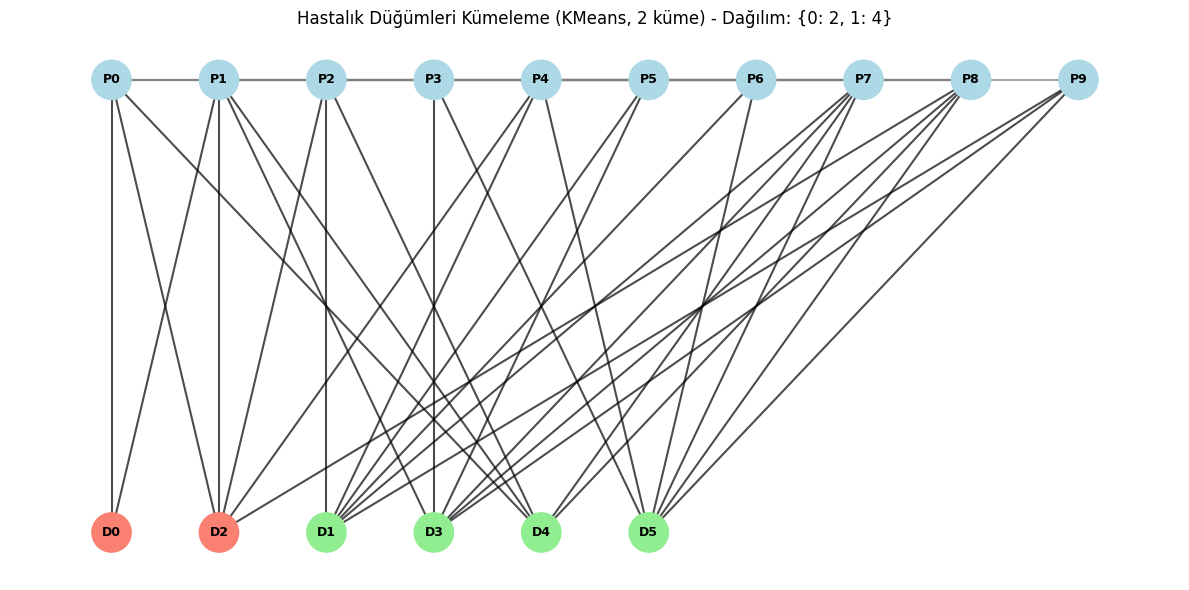

In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import os
from scipy.spatial.distance import cdist

# -------------------------------
# 0. ORTAM DEĞİŞKENLERİ (threadpoolctl hatasını engellemek için)
# -------------------------------
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

# -------------------------------
# 1. PARAMETRELER VE RASTGELE AĞ OLUŞTURMA
# -------------------------------
num_proteins = 10
num_diseases = 6
protein_feat_dim = 3
embedding_dim = 8
hidden_dim = 16

protein_features = torch.randn(num_proteins, protein_feat_dim)  # 10x3
disease_features = torch.zeros(num_diseases, protein_feat_dim)  # 6x3

protein_names = [f"P{i}" for i in range(num_proteins)]
disease_names = [f"D{i}" for i in range(num_diseases)]

np.random.seed(42)  # tekrarlanabilirlik için
G = nx.Graph()
G.add_nodes_from(protein_names, type='protein')
G.add_nodes_from(disease_names, type='disease')

# Protein-Protein kenarları
for i in range(num_proteins):
    for j in range(i+1, num_proteins):
        if np.random.rand() < 0.2:
            G.add_edge(protein_names[i], protein_names[j], type='pp')

# Protein-Hastalık kenarları
for i in range(num_proteins):
    k = np.random.randint(2, 5)
    targets = np.random.choice(num_diseases, size=k, replace=False)
    for t in targets:
        G.add_edge(protein_names[i], disease_names[t], type='pd')

# -------------------------------
# 2. PYTORCH GEOMETRIC VERİ YAPISINA DÖNÜŞTÜR
# -------------------------------
disease_offset = num_proteins
edge_index = []
for u, v in G.edges():
    if u in protein_names:
        u_idx = protein_names.index(u)
    else:
        u_idx = disease_offset + disease_names.index(u)
    if v in protein_names:
        v_idx = protein_names.index(v)
    else:
        v_idx = disease_offset + disease_names.index(v)
    edge_index.append([u_idx, v_idx])
edge_index = torch.tensor(edge_index, dtype=torch.long).t()

all_features = torch.cat([protein_features, disease_features], dim=0)  # (16, 3)

# -------------------------------
# 3. BASİT GNN MODELİ (çıktı boyutu protein_feat_dim)
# -------------------------------
class SimpleGNNForFeatures(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim):
        super().__init__()
        self.lin1 = nn.Linear(in_dim, hidden_dim)
        self.lin2 = nn.Linear(hidden_dim, out_dim)
    
    def forward(self, x, edge_index):
        num_nodes = x.size(0)
        adj = torch.zeros(num_nodes, num_nodes, device=x.device)
        adj[edge_index[0], edge_index[1]] = 1
        adj[edge_index[1], edge_index[0]] = 1
        neighbor_sum = adj @ x
        degree = adj.sum(dim=1, keepdim=True).clamp(min=1)
        neighbor_avg = neighbor_sum / degree
        new_x = x + neighbor_avg
        h = torch.relu(self.lin1(new_x))
        out = self.lin2(h)
        return out

model = SimpleGNNForFeatures(in_dim=protein_feat_dim, hidden_dim=hidden_dim, out_dim=protein_feat_dim)
optimizer = optim.Adam(model.parameters(), lr=0.01)
criterion = nn.MSELoss()

# -------------------------------
# 4. EĞİTİM (protein özelliklerini tahmin etme)
# -------------------------------
print("Model eğitiliyor...")
for epoch in range(300):
    model.train()
    optimizer.zero_grad()
    pred_features = model(all_features, edge_index)
    loss = criterion(pred_features[:num_proteins], protein_features)
    loss.backward()
    optimizer.step()
    if epoch % 100 == 0:
        print(f"Epoch {epoch:3d} | Loss: {loss.item():.6f}")

# -------------------------------
# 5. HASTALIK EMBEDDING'LERİNİ AL VE MANUEL K-MEANS İLE KÜMELE
# -------------------------------
model.eval()
with torch.no_grad():
    embeddings = model(all_features, edge_index)  # (16, 3)
    disease_embeddings = embeddings[num_proteins:]  # (6, 3)
    disease_embeddings_np = disease_embeddings.numpy()

# Manuel K-means (thread hatası yok)
def manual_kmeans(data, k, max_iters=100):
    np.random.seed(42)
    centroids = data[np.random.choice(data.shape[0], k, replace=False)]
    for _ in range(max_iters):
        distances = cdist(data, centroids, metric='euclidean')
        labels = np.argmin(distances, axis=1)
        new_centroids = np.array([data[labels == i].mean(axis=0) if np.any(labels==i) else centroids[i] for i in range(k)])
        if np.allclose(centroids, new_centroids):
            break
        centroids = new_centroids
    return labels

cluster_labels = manual_kmeans(disease_embeddings_np, k=2)
print("\nHastalık küme etiketleri:", cluster_labels)
unique, counts = np.unique(cluster_labels, return_counts=True)
print(f"Küme dağılımı: {dict(zip(unique, counts))}")

# -------------------------------
# 6. GRAFİĞİ RENKLENDİR VE GÖRSELLEŞTİR
# -------------------------------
node_colors = []
for node in G.nodes():
    if node in protein_names:
        node_colors.append('lightblue')
    else:
        idx = disease_names.index(node)
        if cluster_labels[idx] == 0:
            node_colors.append('salmon')
        else:
            node_colors.append('lightgreen')

edge_colors = []
for u, v in G.edges():
    if u in protein_names and v in protein_names:
        edge_colors.append('gray')
    else:
        edge_colors.append('black')

pos = {}
for i, p in enumerate(protein_names):
    pos[p] = (i, 2)

cluster0_nodes = [disease_names[i] for i in range(num_diseases) if cluster_labels[i] == 0]
cluster1_nodes = [disease_names[i] for i in range(num_diseases) if cluster_labels[i] == 1]
for i, d in enumerate(cluster0_nodes):
    pos[d] = (i, 0)
for i, d in enumerate(cluster1_nodes):
    pos[d] = (len(cluster0_nodes) + i, 0)

plt.figure(figsize=(12, 6))
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=800)
nx.draw_networkx_edges(G, pos, edge_color=edge_colors, width=1.5, alpha=0.7)
nx.draw_networkx_labels(G, pos, font_size=9, font_weight='bold')
plt.title(f"Hastalık Düğümleri Kümeleme (KMeans, 2 küme) - Dağılım: {dict(zip(unique, counts))}", fontsize=12)
plt.axis('off')
plt.tight_layout()
plt.show()

In [107]:
#görsel

Protein özellikleri (10x3):
[[-1.8646151  -0.3047366  -0.7960667 ]
 [ 1.0411808   0.84313715 -1.3821691 ]
 [ 1.1371057   0.9460629  -0.544721  ]
 [-0.18249004 -0.8833854  -0.6668389 ]
 [ 0.77700496 -0.55134076 -0.04361525]
 [ 0.62019557 -1.3139325   0.12448475]
 [-0.1164311  -1.5331627  -0.721637  ]
 [ 1.6825954   1.6374533  -0.7669764 ]
 [ 0.04512666 -0.1472058  -0.4484076 ]
 [-1.181821    0.21548295  1.586434  ]]


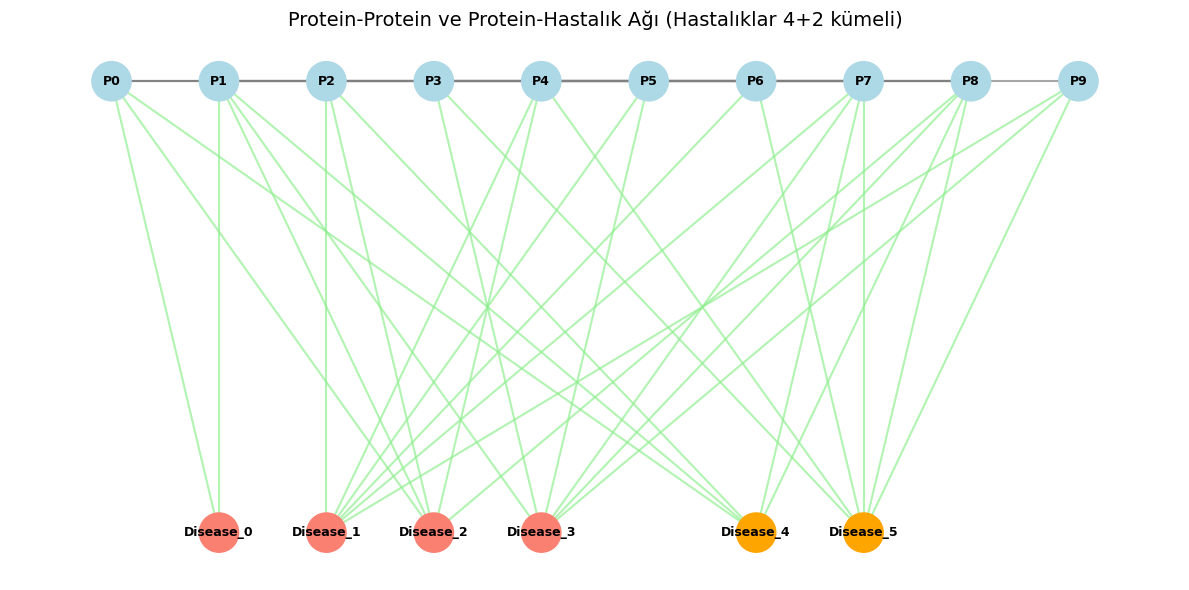


Toplam düğüm sayısı: 16
Protein-Protein kenar sayısı: 14
Protein-Hastalık kenar sayısı: 30


In [105]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import torch

# -------------------------------
# 1. PARAMETRELER
# -------------------------------
num_proteins = 10
num_diseases = 6
protein_feature_dim = 3

# Rastgele protein özellikleri (3 boyutlu)
protein_features = torch.randn(num_proteins, protein_feature_dim)
print("Protein özellikleri (10x3):")
print(protein_features.numpy())

# Hastalık düğümleri (özellik yok, sadece etiket)
disease_names = [f"Disease_{i}" for i in range(num_diseases)]

# -------------------------------
# 2. GRAFİĞİ OLUŞTUR
# -------------------------------
G = nx.Graph()

# Düğümleri ekle
protein_nodes = [f"P{i}" for i in range(num_proteins)]
disease_nodes = disease_names

G.add_nodes_from(protein_nodes, type='protein')
G.add_nodes_from(disease_nodes, type='disease')

# Protein-Protein kenarları (rastgele, her protein ortalama 2-3 bağlantı)
np.random.seed(42)
for i in range(num_proteins):
    # Her protein, diğer proteinlerle %20 olasılıkla bağlansın (yaklaşık 2 kenar)
    for j in range(i+1, num_proteins):
        if np.random.rand() < 0.2:
            G.add_edge(f"P{i}", f"P{j}", layer='protein-protein')

# Protein-Hastalık kenarları (rastgele, her protein ortalama 2-3 hastalık)
for i in range(num_proteins):
    # Hangi hastalıklara bağlanacağı: rastgele 2-4 tane
    num_links = np.random.randint(2, 5)
    selected_diseases = np.random.choice(num_diseases, size=num_links, replace=False)
    for d_idx in selected_diseases:
        G.add_edge(f"P{i}", disease_nodes[d_idx], layer='protein-disease')

# -------------------------------
# 3. HASTALIK DÜĞÜMLERİNİ KÜMELE (4 ve 2)
# -------------------------------
# Küme 1: ilk 4 hastalık (Disease_0 ... Disease_3)
# Küme 2: son 2 hastalık (Disease_4, Disease_5)
cluster1 = disease_nodes[:4]
cluster2 = disease_nodes[4:]

# Düğüm renkleri: proteinler mavi, hastalık küme1 kırmızı, küme2 turuncu
node_colors = []
for node in G.nodes():
    if node in protein_nodes:
        node_colors.append('lightblue')
    elif node in cluster1:
        node_colors.append('salmon')
    else:
        node_colors.append('orange')

# Kenar renkleri: protein-protein gri, protein-hastalık yeşil
edge_colors = []
for u, v in G.edges():
    if u in protein_nodes and v in protein_nodes:
        edge_colors.append('gray')
    else:
        edge_colors.append('lightgreen')

# -------------------------------
# 4. GÖRSELLEŞTİRME (Konumlandırma)
# -------------------------------
# Düzenli yerleşim: proteinler üst, hastalıklar alt, kümeler ayrı
pos = {}
# Proteinler: x = 0..9, y = 2
for i, prot in enumerate(protein_nodes):
    pos[prot] = (i, 2)
# Hastalıklar: x = kümeler halinde, y = 0
# Küme1 (4 hastalık) x = 1,2,3,4   Küme2 (2 hastalık) x = 6,7
for i, dis in enumerate(cluster1):
    pos[dis] = (i+1, 0)
for i, dis in enumerate(cluster2):
    pos[dis] = (i+6, 0)

plt.figure(figsize=(12, 6))
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=800)
nx.draw_networkx_edges(G, pos, edge_color=edge_colors, width=1.5, alpha=0.7)
nx.draw_networkx_labels(G, pos, font_size=9, font_weight='bold')
plt.title("Protein-Protein ve Protein-Hastalık Ağı (Hastalıklar 4+2 kümeli)", fontsize=14)
plt.axis('off')
plt.tight_layout()
plt.show()

# -------------------------------
# 5. AĞ İSTATİSTİKLERİ (isteğe bağlı)
# -------------------------------
print(f"\nToplam düğüm sayısı: {G.number_of_nodes()}")
print(f"Protein-Protein kenar sayısı: {sum(1 for u,v in G.edges() if u in protein_nodes and v in protein_nodes)}")
print(f"Protein-Hastalık kenar sayısı: {sum(1 for u,v in G.edges() if u in protein_nodes and v in disease_nodes)}")

# görselleştirmeler

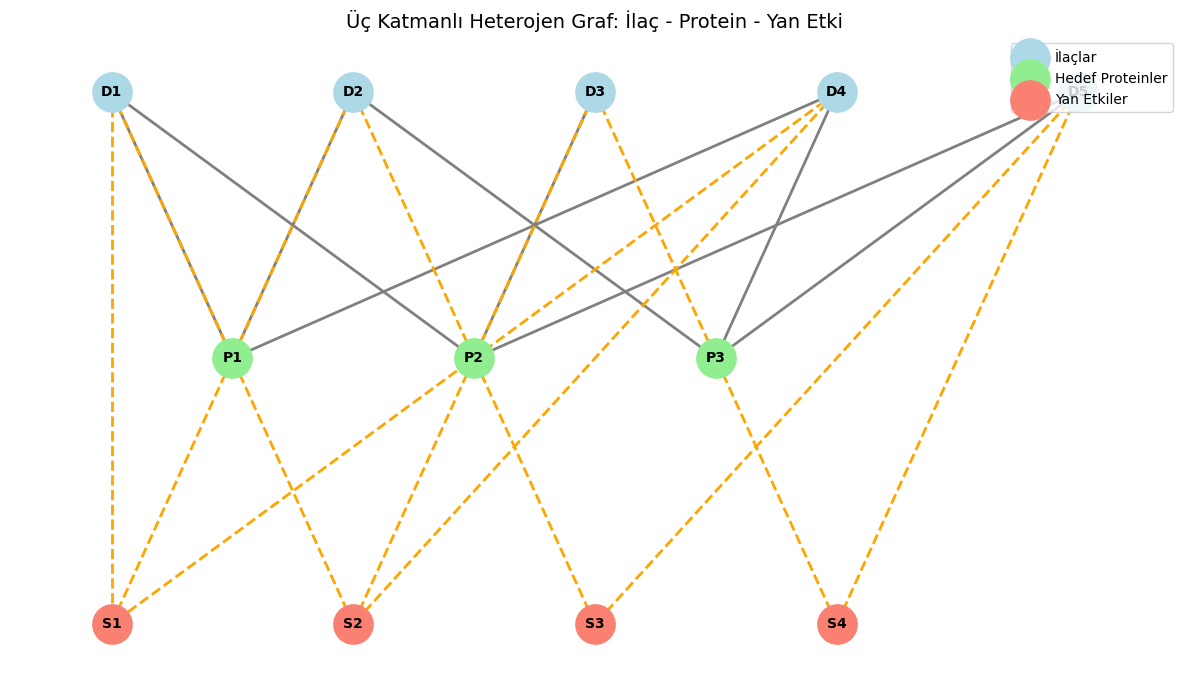

In [69]:
import networkx as nx
import matplotlib.pyplot as plt

# 1. Grafik nesnesini oluştur
G = nx.Graph()

# 2. Düğümleri ekle (örnek sayılar)
drugs = ['D1', 'D2', 'D3', 'D4', 'D5']        # ilaçlar (antibiyotikler)
proteins = ['P1', 'P2', 'P3']                 # hedef proteinler
side_effects = ['S1', 'S2', 'S3', 'S4']       # yan etkiler

G.add_nodes_from(drugs, layer='drug')
G.add_nodes_from(proteins, layer='protein')
G.add_nodes_from(side_effects, layer='side_effect')

# 3. Kenarları ekle (örnek bağlantılar)
# İlaç - Protein etkileşimleri (bağlanma)
drug_protein_edges = [
    ('D1', 'P1'), ('D1', 'P2'),
    ('D2', 'P1'), ('D2', 'P3'),
    ('D3', 'P2'),
    ('D4', 'P3'), ('D4', 'P1'),
    ('D5', 'P2'), ('D5', 'P3')
]

# İlaç - Yan etki ilişkileri (neden olma) - HATALI OLAN ('D4','4') DÜZELTİLDİ
drug_side_edges = [
    ('D1', 'S1'), ('D1', 'S2'),
    ('D2', 'S1'), ('D2', 'S3'),
    ('D3', 'S2'), ('D3', 'S4'),
    ('D4', 'S1'), ('D4', 'S2'),   # Düzeltme: '4' yerine 'S2'
    ('D5', 'S3'), ('D5', 'S4')
]

G.add_edges_from(drug_protein_edges, type='interaction')
G.add_edges_from(drug_side_edges, type='side_effect')

# 4. Düğümlerin konumlarını katmanlara göre manuel olarak ayarla (katmanlı görünüm için)
pos = {}
# İlaç katmanı (yukarı, x = indeks)
for i, drug in enumerate(drugs):
    pos[drug] = (i, 2)
# Protein katmanı (orta, x = rastgele dağılım - daha düzenli olması için indeks kullandım)
for i, protein in enumerate(proteins):
    pos[protein] = (i + 0.5, 1)
# Yan etki katmanı (aşağı, x = indeks)
for i, se in enumerate(side_effects):
    pos[se] = (i, 0)

# 5. Çizim
plt.figure(figsize=(12, 7))

# Düğümleri renklendir ve çiz
nx.draw_networkx_nodes(G, pos, nodelist=drugs, node_color='lightblue', node_size=800, label='İlaçlar')
nx.draw_networkx_nodes(G, pos, nodelist=proteins, node_color='lightgreen', node_size=800, label='Hedef Proteinler')
nx.draw_networkx_nodes(G, pos, nodelist=side_effects, node_color='salmon', node_size=800, label='Yan Etkiler')

# Kenarları çiz (ilaç-protein: düz gri, ilaç-yan etki: kesik turuncu)
nx.draw_networkx_edges(G, pos, edgelist=drug_protein_edges, edge_color='gray', width=2, style='solid')
nx.draw_networkx_edges(G, pos, edgelist=drug_side_edges, edge_color='orange', width=2, style='dashed')

# Düğüm etiketlerini ekle
nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

# Legend ve başlık
plt.legend(loc='upper right', fontsize=10)
plt.title("Üç Katmanlı Heterojen Graf: İlaç - Protein - Yan Etki", fontsize=14)
plt.axis('off')
plt.tight_layout()
plt.show()

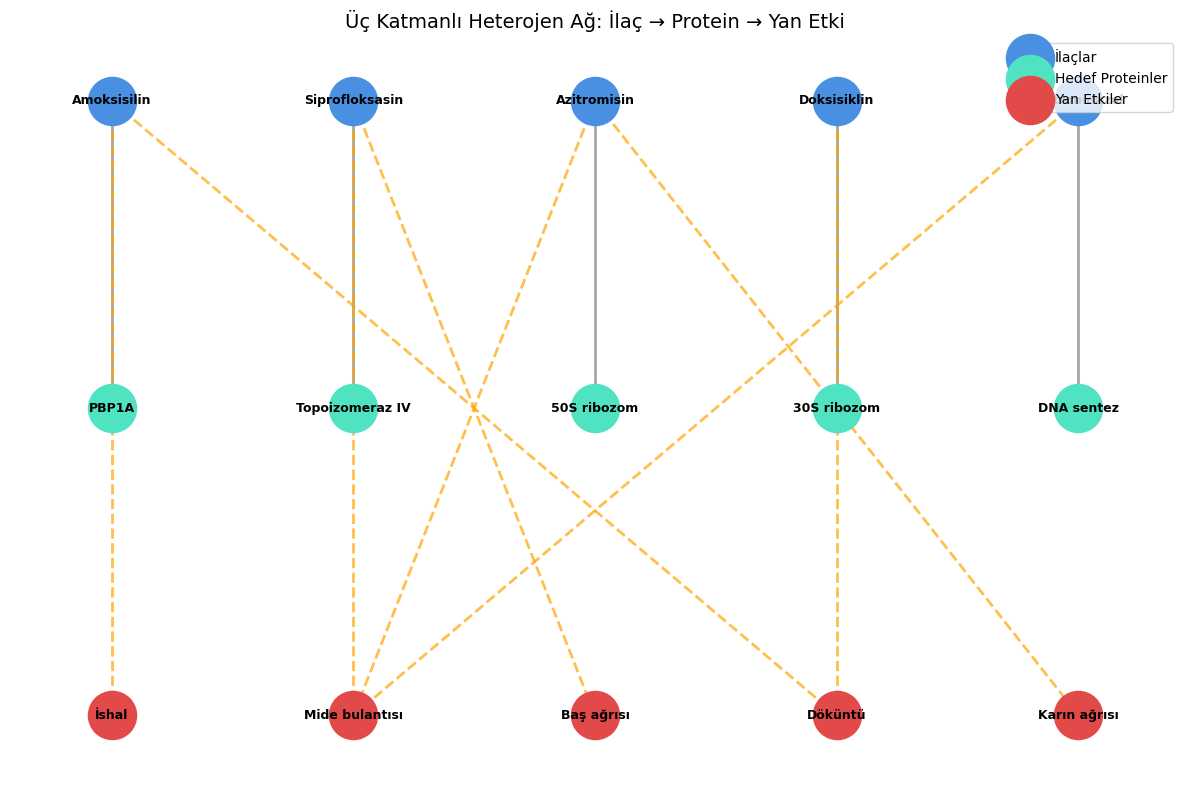

In [74]:
import networkx as nx
import matplotlib.pyplot as plt

# Grafik oluştur
G = nx.Graph()

# Düğümler (katmanlar)
drugs = ['Amoksisilin', 'Siprofloksasin', 'Azitromisin', 'Doksisiklin', 'Metronidazol']
proteins = ['PBP1A', 'Topoizomeraz IV', '50S ribozom', '30S ribozom', 'DNA sentez']
side_effects = ['İshal', 'Mide bulantısı', 'Baş ağrısı', 'Döküntü', 'Karın ağrısı']

# Düğümleri ekle
G.add_nodes_from(drugs, layer='drug')
G.add_nodes_from(proteins, layer='protein')
G.add_nodes_from(side_effects, layer='side_effect')

# İlaç-Protein bağlantıları (gerçek veri yok, örnek)
drug_protein = [
    ('Amoksisilin', 'PBP1A'),
    ('Siprofloksasin', 'Topoizomeraz IV'),
    ('Azitromisin', '50S ribozom'),
    ('Doksisiklin', '30S ribozom'),
    ('Metronidazol', 'DNA sentez')
]

# İlaç-Yan etki bağlantıları (örnek)
drug_side = [
    ('Amoksisilin', 'İshal'),
    ('Amoksisilin', 'Döküntü'),
    ('Siprofloksasin', 'Mide bulantısı'),
    ('Siprofloksasin', 'Baş ağrısı'),
    ('Azitromisin', 'Karın ağrısı'),
    ('Azitromisin', 'Mide bulantısı'),
    ('Doksisiklin', 'Döküntü'),
    ('Metronidazol', 'Mide bulantısı')
]

G.add_edges_from(drug_protein, type='interaction')
G.add_edges_from(drug_side, type='side_effect')

# Konumlandırma (katmanlar halinde)
pos = {}
for i, drug in enumerate(drugs):
    pos[drug] = (i, 2)               # ilaçlar üstte
for i, protein in enumerate(proteins):
    pos[protein] = (i, 1)            # proteinler ortada
for i, se in enumerate(side_effects):
    pos[se] = (i, 0)                 # yan etkiler altta

# Çizim
plt.figure(figsize=(12, 8))
# Düğümleri çiz
nx.draw_networkx_nodes(G, pos, nodelist=drugs, node_color='#4A90E2', node_size=1200, label='İlaçlar')
nx.draw_networkx_nodes(G, pos, nodelist=proteins, node_color='#50E3C2', node_size=1200, label='Hedef Proteinler')
nx.draw_networkx_nodes(G, pos, nodelist=side_effects, node_color='#E24A4A', node_size=1200, label='Yan Etkiler')
# Kenarları çiz
nx.draw_networkx_edges(G, pos, edgelist=drug_protein, edge_color='gray', width=2, style='solid', alpha=0.7)
nx.draw_networkx_edges(G, pos, edgelist=drug_side, edge_color='orange', width=2, style='dashed', alpha=0.7)
# Etiketler
nx.draw_networkx_labels(G, pos, font_size=9, font_weight='bold')
# Başlık ve gösterim
plt.title("Üç Katmanlı Heterojen Ağ: İlaç → Protein → Yan Etki", fontsize=14)
plt.legend(loc='upper right', fontsize=10)
plt.axis('off')
plt.tight_layout()
plt.show()

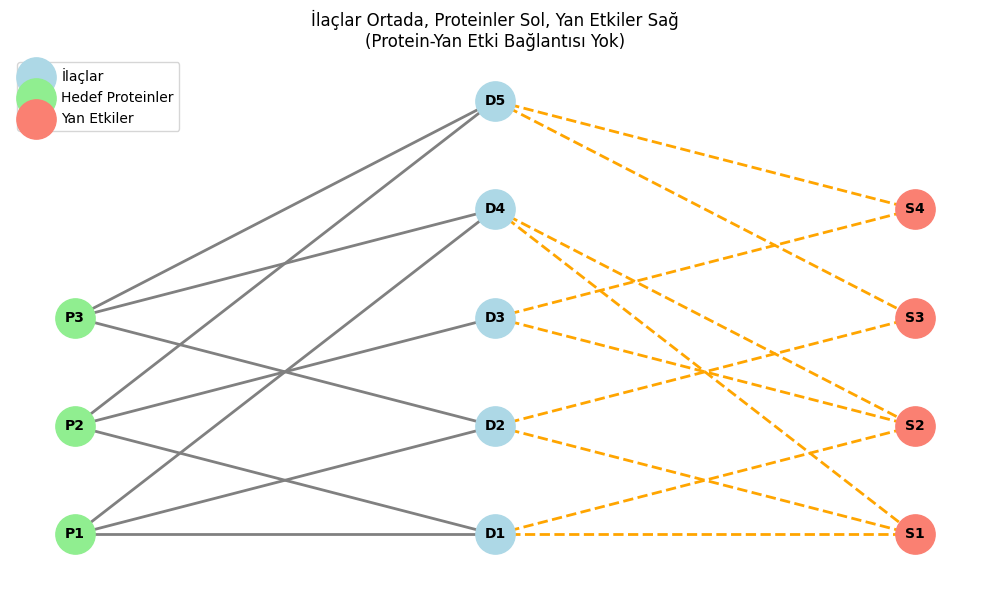

In [77]:
import networkx as nx
import matplotlib.pyplot as plt

# 1. Grafik oluştur
G = nx.Graph()

# 2. Düğümler
drugs = ['D1', 'D2', 'D3', 'D4', 'D5']
proteins = ['P1', 'P2', 'P3']
side_effects = ['S1', 'S2', 'S3', 'S4']

G.add_nodes_from(drugs, layer='drug')
G.add_nodes_from(proteins, layer='protein')
G.add_nodes_from(side_effects, layer='side_effect')

# 3. Kenarlar (örnek bağlantılar)
# İlaç-protein
drug_protein_edges = [
    ('D1','P1'), ('D1','P2'),
    ('D2','P1'), ('D2','P3'),
    ('D3','P2'),
    ('D4','P3'), ('D4','P1'),
    ('D5','P2'), ('D5','P3')
]
# İlaç-yan etki (sadece ilaç-yan etki)
drug_side_edges = [
    ('D1','S1'), ('D1','S2'),
    ('D2','S1'), ('D2','S3'),
    ('D3','S2'), ('D3','S4'),
    ('D4','S1'), ('D4','S2'),
    ('D5','S3'), ('D5','S4')
]

G.add_edges_from(drug_protein_edges, type='interaction')
G.add_edges_from(drug_side_edges, type='side_effect')

# 4. Konumlandırma: ilaçlar ortada (x=0), proteinler sol (x=-2), yan etkiler sağ (x=2)
#   Y koordinatları ilaçların indeksine göre ayarlanır.
pos = {}

# İlaçlar (x=0, y = 0,1,2,3,4)
for i, drug in enumerate(drugs):
    pos[drug] = (0, i)

# Proteinler (x=-2, y = 0,1,2,... protein sayısı kadar, aynı y'ler ilaçlarla çakışabilir ama farklı x olduğu için sorun yok)
for i, prot in enumerate(proteins):
    pos[prot] = (-2, i)

# Yan etkiler (x=2, y = 0,1,2,...)
for i, se in enumerate(side_effects):
    pos[se] = (2, i)

# 5. Çizim
plt.figure(figsize=(10, 6))

# Düğümleri çiz
nx.draw_networkx_nodes(G, pos, nodelist=drugs, node_color='lightblue', node_size=800, label='İlaçlar')
nx.draw_networkx_nodes(G, pos, nodelist=proteins, node_color='lightgreen', node_size=800, label='Hedef Proteinler')
nx.draw_networkx_nodes(G, pos, nodelist=side_effects, node_color='salmon', node_size=800, label='Yan Etkiler')

# Kenarları çiz (ilaç-protein düz gri, ilaç-yan etki kesik turuncu)
nx.draw_networkx_edges(G, pos, edgelist=drug_protein_edges, edge_color='gray', width=2, style='solid')
nx.draw_networkx_edges(G, pos, edgelist=drug_side_edges, edge_color='orange', width=2, style='dashed')

# Etiketler
nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

plt.legend(loc='upper left', fontsize=10)
plt.title("İlaçlar Ortada, Proteinler Sol, Yan Etkiler Sağ\n(Protein-Yan Etki Bağlantısı Yok)", fontsize=12)
plt.axis('off')
plt.tight_layout()
plt.show()